# Phân tích bán hàng với PySpark

## Sales Analytics with PySpark – UCI Online Retail II

**Mục tiêu:** xử lý hơn 1 triệu giao dịch và chuyển dữ liệu thành KPI, insight và đề xuất kinh doanh.

## Dataset
- **UCI Online Retail II**
- 1,067,371 giao dịch trong hai năm
- Nguồn: https://archive.ics.uci.edu/dataset/502/online+retail+ii
- DOI: 10.24432/C5CG6D
- License: CC BY 4.0

> Dataset gốc là Excel gồm hai sheet. Phần setup dưới đây tải và chuyển từng sheet sang CSV trước khi Spark đọc.

## Cài đặt và khởi tạo Spark

In [ ]:
!pip -q install pyspark pandas openpyxl

In [ ]:
from pyspark.sql import SparkSession, functions as F, Window
from pyspark.sql.types import *

spark = (SparkSession.builder
         .appName('SalesAnalyticsOnlineRetailII')
         .getOrCreate())

print('Spark version:', spark.version)

Spark version: 4.0.4


## Tải dữ liệu từ UCI và chuyển Excel sang CSV
Chạy cell này trên Colab/Jupyter có Internet. Nếu đã có `online_retail_II.csv`, có thể bỏ qua.

In [ ]:
import os, zipfile, urllib.request, pandas as pd

URL = 'https://archive.ics.uci.edu/static/public/502/online%2Bretail%2Bii.zip'
ZIP_PATH = 'online_retail_II.zip'
EXTRACT_DIR = 'online_retail_II_raw'
CSV_PATH = 'online_retail_II.csv'

if not os.path.exists(CSV_PATH):
    if not os.path.exists(ZIP_PATH):
        urllib.request.urlretrieve(URL, ZIP_PATH)
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(EXTRACT_DIR)

    xlsx_files = [os.path.join(EXTRACT_DIR, f) for f in os.listdir(EXTRACT_DIR) if f.lower().endswith('.xlsx')]
    assert xlsx_files, 'Không tìm thấy file .xlsx'
    xlsx_path = xlsx_files[0]
    book = pd.ExcelFile(xlsx_path)
    first = True
    for sheet in book.sheet_names:
        print('Converting:', sheet)
        pdf = pd.read_excel(xlsx_path, sheet_name=sheet)
        pdf.to_csv(CSV_PATH, mode='w' if first else 'a', index=False, header=first)
        first = False
    print('Created:', CSV_PATH)
else:
    print('Found:', CSV_PATH)

Converting: Year 2009-2010
Converting: Year 2010-2011
Created: online_retail_II.csv


## 1. Data Understanding

In [ ]:
sales_raw = spark.read.option('header', True).option('inferSchema', True).csv('online_retail_II.csv')
sales_raw.show(10, truncate=False)
sales_raw.printSchema()

+-------+---------+-----------------------------------+--------+-------------------+-----+-----------+--------------+
|Invoice|StockCode|Description                        |Quantity|InvoiceDate        |Price|Customer ID|Country       |
+-------+---------+-----------------------------------+--------+-------------------+-----+-----------+--------------+
|489434 |85048    |15CM CHRISTMAS GLASS BALL 20 LIGHTS|12      |2009-12-01 07:45:00|6.95 |13085.0    |United Kingdom|
|489434 |79323P   |PINK CHERRY LIGHTS                 |12      |2009-12-01 07:45:00|6.75 |13085.0    |United Kingdom|
|489434 |79323W   | WHITE CHERRY LIGHTS               |12      |2009-12-01 07:45:00|6.75 |13085.0    |United Kingdom|
|489434 |22041    |"RECORD FRAME 7"" SINGLE SIZE "    |48      |2009-12-01 07:45:00|2.1  |13085.0    |United Kingdom|
|489434 |21232    |STRAWBERRY CERAMIC TRINKET BOX     |24      |2009-12-01 07:45:00|1.25 |13085.0    |United Kingdom|
|489434 |22064    |PINK DOUGHNUT TRINKET POT          |2

In [ ]:
print('Rows:', sales_raw.count())
print('Columns:', len(sales_raw.columns))
print(sales_raw.columns)

Rows: 1067371
Columns: 8
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


### Bài tập 1. Khám phá dữ liệu
1. Đếm số hóa đơn, sản phẩm, khách hàng và quốc gia phân biệt.
2. Xác định min/max InvoiceDate.
3. Giải thích vì sao số dòng lớn hơn số hóa đơn.

In [ ]:
sales_raw.select(
    F.countDistinct('Invoice').alias('Invoices') if 'Invoice' in sales_raw.columns else F.countDistinct('InvoiceNo').alias('Invoices')
).show()

+--------+
|Invoices|
+--------+
|   53628|
+--------+



> **Lưu ý:** UCI Online Retail II có thể dùng tên cột `Invoice`, `Price`, `Customer ID` thay vì `InvoiceNo`, `UnitPrice`, `CustomerID` tùy phiên bản file. Cell sau chuẩn hóa tên cột để phần còn lại của notebook thống nhất.

In [ ]:
rename_map = {
    'Invoice':'InvoiceNo',
    'Price':'UnitPrice',
    'Customer ID':'CustomerID'
}
df = sales_raw
for old, new in rename_map.items():
    if old in df.columns:
        df = df.withColumnRenamed(old, new)
print(df.columns)

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


## 2. Kiểm tra missing values và dữ liệu bất thường

In [ ]:
missing = df.select([F.sum(F.col(c).isNull().cast('int')).alias(c) for c in df.columns])
missing.show(truncate=False)

+---------+---------+-----------+--------+-----------+---------+----------+-------+
|InvoiceNo|StockCode|Description|Quantity|InvoiceDate|UnitPrice|CustomerID|Country|
+---------+---------+-----------+--------+-----------+---------+----------+-------+
|0        |0        |4382       |0       |0          |0        |243007    |0      |
+---------+---------+-----------+--------+-----------+---------+----------+-------+



In [ ]:
df.select(
    F.sum((F.col('Quantity') <= 0).cast('int')).alias('Quantity_le_0'),
    F.sum((F.col('UnitPrice') <= 0).cast('int')).alias('UnitPrice_le_0'),
    F.sum(F.col('InvoiceNo').cast('string').startswith('C').cast('int')).alias('CancelledRows')
).show()

+-------------+--------------+-------------+
|Quantity_le_0|UnitPrice_le_0|CancelledRows|
+-------------+--------------+-------------+
|        22950|          6207|        19494|
+-------------+--------------+-------------+



### Bài tập 2. Data Cleaning
Tạo `sales_clean` với các giao dịch bán hợp lệ và `sales_customer` chỉ gồm các dòng có CustomerID.

In [ ]:
df = df.withColumn('InvoiceDate', F.to_timestamp('InvoiceDate'))

df = df.withColumn('IsCancelled', F.col('InvoiceNo').cast('string').startswith('C'))

sales_clean = df.filter(
    (~F.col('IsCancelled')) &
    (F.col('Quantity') > 0) &
    (F.col('UnitPrice') > 0)
)

sales_customer = sales_clean.filter(F.col('CustomerID').isNotNull())

print('Raw rows:', df.count())
print('Clean rows:', sales_clean.count())
print('Customer rows:', sales_customer.count())

Raw rows: 1067371
Clean rows: 1041670
Customer rows: 805549


In [ ]:
# Missing còn lại trong sales_clean
sales_clean.select([F.sum(F.col(c).isNull().cast('int')).alias(c)
                    for c in ['Description', 'CustomerID']]).show()

# Dòng trùng lặp
print('Clean rows:', sales_clean.count())
print('Sau khi bỏ trùng:', sales_clean.dropDuplicates().count())

# StockCode không theo dạng số (thường là mã phí, dịch vụ)
(sales_clean.filter(~F.col('StockCode').rlike('^[0-9]{5}'))
            .groupBy('StockCode', 'Description')
            .agg(F.count('*').alias('Rows'), F.round(F.sum(F.col('Quantity')*F.col('UnitPrice')), 2).alias('Revenue'))
            .orderBy(F.desc('Revenue'))
            .show(20, truncate=False))

# Ngoại lai: các dòng có Quantity hoặc UnitPrice lớn nhất
sales_clean.orderBy(F.desc('Quantity')).show(5, truncate=False)
sales_clean.orderBy(F.desc('UnitPrice')).show(5, truncate=False)

+-----------+----------+
|Description|CustomerID|
+-----------+----------+
|          0|    236121|
+-----------+----------+

Clean rows: 1041670
Sau khi bỏ trùng: 1007913
+------------+-----------------------------------+----+---------+
|StockCode   |Description                        |Rows|Revenue  |
+------------+-----------------------------------+----+---------+
|M           |Manual                             |876 |340716.28|
|DOT         |DOTCOM POSTAGE                     |1436|322657.48|
|POST        |POSTAGE                            |1886|127597.42|
|AMAZONFEE   |AMAZON FEE                         |4   |34009.13 |
|C2          |CARRIAGE                           |272 |13676.0  |
|B           |Adjust bad debt                    |1   |11062.06 |
|ADJUST      |Adjustment by john on 26/01/2010 17|16  |6563.5   |
|ADJUST      |Adjustment by john on 26/01/2010 16|20  |2334.43  |
|ADJUST2     |Adjustment by Peter on Jun 25 2010 |3   |731.05   |
|gift_0001_30|Dotcomgiftshop Gift Vo

## Kiểm tra dữ liệu thiếu CustomerID
Kiểm tra số lượng dòng có và thiếu CustomerID trên bộ dữ liệu gốc nhằm đánh giá mức độ đầy đủ của thông tin khách hàng trước khi tiến hành làm sạch và phân tích.

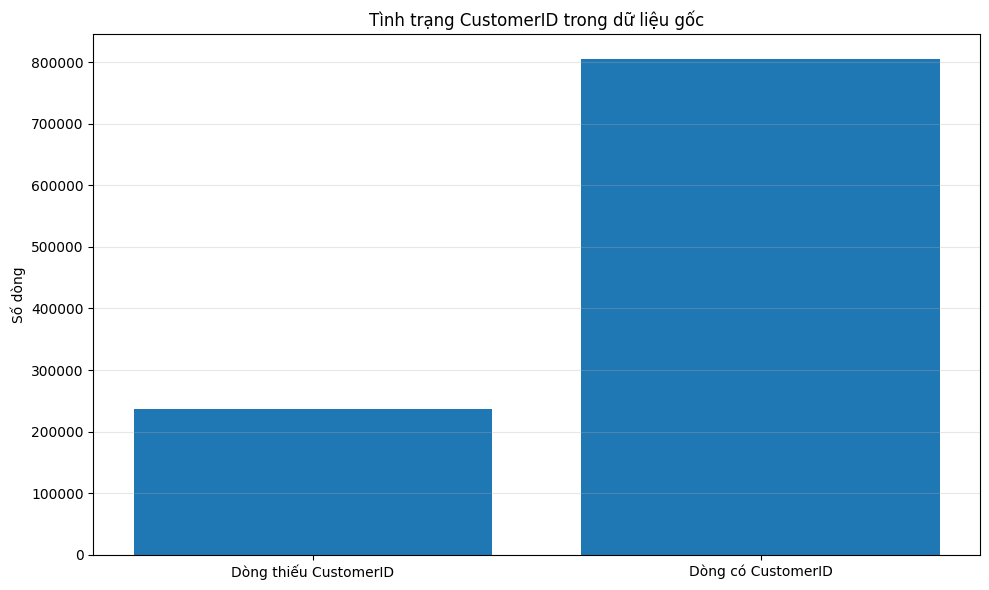

In [57]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# Đếm số dòng có và thiếu CustomerID trong dữ liệu gốc
missing_customer = sales.filter(
    F.col("CustomerID").isNull()
).count()

available_customer = sales.filter(
    F.col("CustomerID").isNotNull()
).count()

# Vẽ biểu đồ
labels = ["Dòng thiếu CustomerID", "Dòng có CustomerID"]
values = [missing_customer, available_customer]

plt.figure(figsize=(10, 6))
plt.bar(labels, values)
plt.title("Tình trạng CustomerID trong dữ liệu gốc")
plt.ylabel("Số dòng")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Feature Engineering

In [ ]:
sales = (sales_clean
    .withColumn('Revenue', F.col('Quantity') * F.col('UnitPrice'))
    .withColumn('Date', F.to_date('InvoiceDate'))
    .withColumn('Year', F.year('InvoiceDate'))
    .withColumn('Month', F.month('InvoiceDate'))
    .withColumn('YearMonth', F.date_format('InvoiceDate', 'yyyy-MM'))
    .withColumn('DayOfWeek', F.date_format('InvoiceDate', 'E'))
    .withColumn('Hour', F.hour('InvoiceDate'))
)

sales.select('InvoiceNo','InvoiceDate','Quantity','UnitPrice','Revenue','YearMonth').show(10)

+---------+-------------------+--------+---------+------------------+---------+
|InvoiceNo|        InvoiceDate|Quantity|UnitPrice|           Revenue|YearMonth|
+---------+-------------------+--------+---------+------------------+---------+
|   489434|2009-12-01 07:45:00|      12|     6.95|              83.4|  2009-12|
|   489434|2009-12-01 07:45:00|      12|     6.75|              81.0|  2009-12|
|   489434|2009-12-01 07:45:00|      12|     6.75|              81.0|  2009-12|
|   489434|2009-12-01 07:45:00|      48|      2.1|100.80000000000001|  2009-12|
|   489434|2009-12-01 07:45:00|      24|     1.25|              30.0|  2009-12|
|   489434|2009-12-01 07:45:00|      24|     1.65|39.599999999999994|  2009-12|
|   489434|2009-12-01 07:45:00|      24|     1.25|              30.0|  2009-12|
|   489434|2009-12-01 07:45:00|      10|     5.95|              59.5|  2009-12|
|   489435|2009-12-01 07:46:00|      12|     2.55|30.599999999999998|  2009-12|
|   489435|2009-12-01 07:46:00|      12|

## 4. KPI tổng quan

In [ ]:
kpi = sales.agg(
    F.sum('Revenue').alias('Revenue'),
    F.countDistinct('InvoiceNo').alias('Orders'),
    F.sum('Quantity').alias('UnitsSold'),
    F.countDistinct('CustomerID').alias('Customers')
).first()

revenue = float(kpi['Revenue'])
orders = int(kpi['Orders'])
units = int(kpi['UnitsSold'])
customers = int(kpi['Customers'])

print(f'Revenue: £{revenue:,.2f}')
print(f'Orders: {orders:,}')
print(f'Units sold: {units:,}')
print(f'Customers: {customers:,}')
print(f'AOV: £{revenue/orders:,.2f}')
print(f'Revenue/customer: £{revenue/customers:,.2f}')
print(f'Items/order: {units/orders:,.2f}')

Revenue: £20,972,594.57
Orders: 40,077
Units sold: 11,420,305
Customers: 5,878
AOV: £523.31
Revenue/customer: £3,567.98
Items/order: 284.96


### Nhận xét
- Sau khi làm sạch, doanh nghiệp ghi nhận khoảng £20,97 triệu doanh thu từ 40.077 đơn hàng hợp lệ và hơn 11,4 triệu sản phẩm bán ra, với 5.878 khách hàng có mã định danh. Đây là quy mô của một nhà bán hàng trực tuyến cỡ vừa, có lượng giao dịch lớn và ổn định trong hai năm dữ liệu.

- Mỗi đơn hàng trung bình trị giá £523,31 và gồm 284,96 sản phẩm, trong khi doanh thu bình quân mỗi sản phẩm chỉ khoảng £1,84 (£20.972.594,57 / 11.420.305). Như vậy công ty bán số lượng lớn với đơn giá thấp, giống mô hình bán sỉ cho đại lý hoặc cửa hàng hơn là bán lẻ cho người tiêu dùng cá nhân.

- Mỗi đơn có trung bình khoảng 26 dòng sản phẩm (1.041.670 dòng / 40.077 đơn). Khách thường mua nhiều mã hàng khác nhau trong cùng một lần đặt, cho thấy danh mục sản phẩm rộng và có dư địa cho bán chéo (cross-sell) cũng như gợi ý sản phẩm đi kèm.

- Doanh thu bình quân mỗi khách hàng là £3.567,98, phản ánh giá trị khách hàng cao. Tuy nhiên con số này đang bị phóng đại: tử số gồm cả doanh thu từ các dòng không có CustomerID (khoảng 22,7% số dòng hợp lệ), còn mẫu số chỉ đếm khách có mã.

- Dữ liệu khá sạch: chỉ khoảng 2,4% số dòng bị loại do hủy, số lượng hoặc giá không hợp lệ. Dù vậy, gần 1/4 số dòng hợp lệ không có mã khách hàng, nên mọi phân tích theo khách hàng (concentration, RFM) phải dùng sales_customer và chỉ đại diện cho khoảng 77% giao dịch.

## 5. Phân tích doanh thu theo thời gian

In [ ]:
monthly = (sales.groupBy('YearMonth')
    .agg(
        F.sum('Revenue').alias('Revenue'),
        F.countDistinct('InvoiceNo').alias('Orders'),
        F.sum('Quantity').alias('Units')
    )
    .withColumn('AOV', F.col('Revenue')/F.col('Orders'))
    .orderBy('YearMonth'))
monthly.show(30, truncate=False)

+---------+------------------+------+------+------------------+
|YearMonth|Revenue           |Orders|Units |AOV               |
+---------+------------------+------+------+------------------+
|2009-12  |825685.7600000007 |1682  |426981|490.8952199762192 |
|2010-01  |652708.5020000001 |1105  |391525|590.6864271493214 |
|2010-02  |553339.7360000005 |1201  |382781|460.7325029142385 |
|2010-03  |833570.1309999995 |1681  |527401|495.87753182629353|
|2010-04  |681528.9919999992 |1462  |368198|466.1621012311896 |
|2010-05  |659858.8600000002 |1500  |397206|439.9059066666668 |
|2010-06  |752270.1400000008 |1645  |408636|457.30707598784244|
|2010-07  |650712.9399999998 |1529  |338920|425.58073250490503|
|2010-08  |697274.91         |1425  |473420|489.3157263157895 |
|2010-09  |924333.0109999999 |1839  |585357|502.628064709081  |
|2010-10  |1165483.9099999995|2301  |622095|506.5119122120815 |
|2010-11  |1470272.4820000017|2747  |728449|535.2284244630512 |
|2010-12  |1262598.7899999998|1559  |540

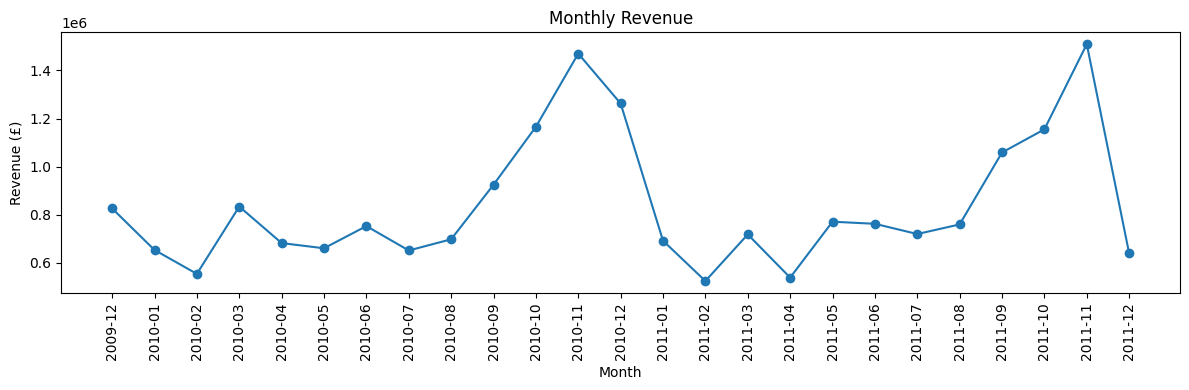

In [ ]:
import matplotlib.pyplot as plt
monthly_pd = monthly.toPandas()
plt.figure(figsize=(12,4))
plt.plot(monthly_pd['YearMonth'], monthly_pd['Revenue'], marker='o')
plt.xticks(rotation=90)
plt.title('Monthly Revenue')
plt.xlabel('Month'); plt.ylabel('Revenue (£)')
plt.tight_layout(); plt.show()

### Bài tập 3
- Tìm 10 ngày doanh thu cao nhất.
- Phân tích doanh thu theo thứ trong tuần.
- Phân tích theo giờ.
- Nhận xét mùa vụ/cao điểm.

In [ ]:
# TODO: doanh thu theo ngày / day-of-week / hour


In [ ]:
# Tìm 10 ngày doanh thu cao nhất
daily = (sales.groupBy('Date', 'DayOfWeek')
    .agg(
        F.round(F.sum('Revenue'), 2).alias('Revenue'),
        F.countDistinct('InvoiceNo').alias('Orders'),
        F.sum('Quantity').alias('Units'),
        F.countDistinct('CustomerID').alias('Customers')
    )
    .withColumn('AOV', F.round(F.col('Revenue') / F.col('Orders'), 2)))

top10_days = daily.orderBy(F.desc('Revenue')).limit(10)
top10_days.show(truncate=False)

+----------+---------+---------+------+------+---------+-------+
|Date      |DayOfWeek|Revenue  |Orders|Units |Customers|AOV    |
+----------+---------+---------+------+------+---------+-------+
|2011-12-09|Fri      |200938.6 |44    |93980 |35       |4566.79|
|2010-12-07|Tue      |199236.4 |84    |50440 |65       |2371.86|
|2010-09-27|Mon      |118909.67|95    |125534|69       |1251.68|
|2010-12-01|Wed      |117921.58|127   |53838 |95       |928.52 |
|2011-11-14|Mon      |114419.89|107   |47353 |93       |1069.34|
|2010-12-06|Mon      |109660.92|102   |43590 |82       |1075.11|
|2011-09-20|Tue      |109612.03|70    |43726 |53       |1565.89|
|2010-12-09|Thu      |107172.36|107   |39860 |90       |1001.61|
|2010-11-15|Mon      |105185.54|103   |38084 |83       |1021.22|
|2011-01-18|Tue      |95978.05 |41    |82978 |31       |2340.93|
+----------+---------+---------+------+------+---------+-------+



+------+---------+----------+------+-------+----------+------+---------+------------+----------+
|DowNum|DayOfWeek|Revenue   |Orders|Units  |ActiveDays|AOV   |RevPerDay|OrdersPerDay|RevShare_%|
+------+---------+----------+------+-------+----------+------+---------+------------+----------+
|2     |Mon      |3644756.59|6351  |2057562|94        |573.89|38774.01 |67.6        |17.38     |
|3     |Tue      |4185862.91|7291  |2173223|104       |574.11|40248.68 |70.1        |19.96     |
|4     |Wed      |3601790.37|7185  |2054847|104       |501.29|34632.6  |69.1        |17.17     |
|5     |Thu      |4306392.17|8288  |2377260|103       |519.59|41809.63 |80.5        |20.53     |
|6     |Fri      |3376979.18|6097  |1698470|99        |553.88|34110.9  |61.6        |16.1      |
|7     |Sat      |9803.05   |30    |5119   |1         |326.77|9803.05  |30.0        |0.05      |
|1     |Sun      |1847010.29|4835  |1053824|99        |382.01|18656.67 |48.8        |8.81      |
+------+---------+----------+-

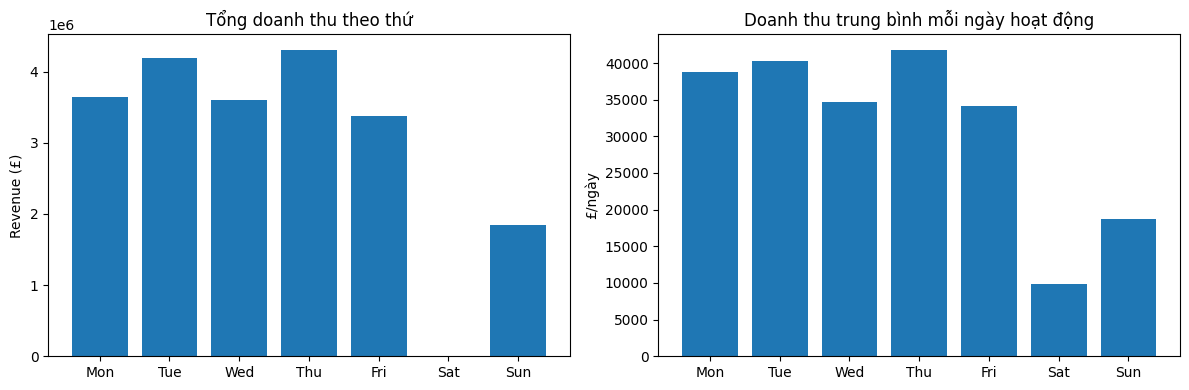

In [ ]:
# Phân tích doanh thu theo thứ trong tuần

dow = (sales
    .withColumn('DowNum', F.dayofweek('InvoiceDate'))          # 1 = Chủ nhật, 2 = Thứ 2, ..., 7 = Thứ 7
    .groupBy('DowNum', 'DayOfWeek')
    .agg(
        F.round(F.sum('Revenue'), 2).alias('Revenue'),
        F.countDistinct('InvoiceNo').alias('Orders'),
        F.sum('Quantity').alias('Units'),
        F.countDistinct('Date').alias('ActiveDays')
    )
    .withColumn('AOV', F.round(F.col('Revenue') / F.col('Orders'), 2))
    .withColumn('RevPerDay', F.round(F.col('Revenue') / F.col('ActiveDays'), 2))
    .withColumn('OrdersPerDay', F.round(F.col('Orders') / F.col('ActiveDays'), 1))
    .withColumn('RevShare_%', F.round(F.col('Revenue') / F.lit(revenue) * 100, 2))
    .withColumn('SortKey', F.when(F.col('DowNum') == 1, 8).otherwise(F.col('DowNum')))  # đưa Chủ nhật xuống cuối
    .orderBy('SortKey')
    .drop('SortKey'))

dow.show(truncate=False)

import matplotlib.pyplot as plt

dow_pd = dow.toPandas()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(dow_pd['DayOfWeek'], dow_pd['Revenue'])
ax[0].set_title('Tổng doanh thu theo thứ'); ax[0].set_ylabel('Revenue (£)')

ax[1].bar(dow_pd['DayOfWeek'], dow_pd['RevPerDay'])
ax[1].set_title('Doanh thu trung bình mỗi ngày hoạt động'); ax[1].set_ylabel('£/ngày')

plt.tight_layout(); plt.show()

+----+----------+------+-------+----------+------+---------+----------+
|Hour|Revenue   |Orders|Units  |ActiveDays|AOV   |RevPerDay|RevShare_%|
+----+----------+------+-------+----------+------+---------+----------+
|6   |4.25      |1     |1      |1         |4.25  |4.25     |0.0       |
|7   |76232.57  |77    |45031  |54        |990.03|1411.71  |0.36      |
|8   |532450.68 |998   |298268 |387       |533.52|1375.84  |2.54      |
|9   |1802195.01|2754  |930598 |500       |654.39|3604.39  |8.59      |
|10  |2629271.8 |4610  |1512937|602       |570.34|4367.56  |12.54     |
|11  |2584521.45|4903  |1472664|602       |527.13|4293.23  |12.32     |
|12  |2910225.35|6427  |1697150|603       |452.81|4826.24  |13.88     |
|13  |2602570.25|5695  |1578508|601       |456.99|4330.4   |12.41     |
|14  |2385595.47|5071  |1214060|601       |470.44|3969.38  |11.37     |
|15  |2478204.48|4566  |1271841|599       |542.75|4137.24  |11.82     |
|16  |1641125.32|2718  |809521 |556       |603.8 |2951.66  |7.83

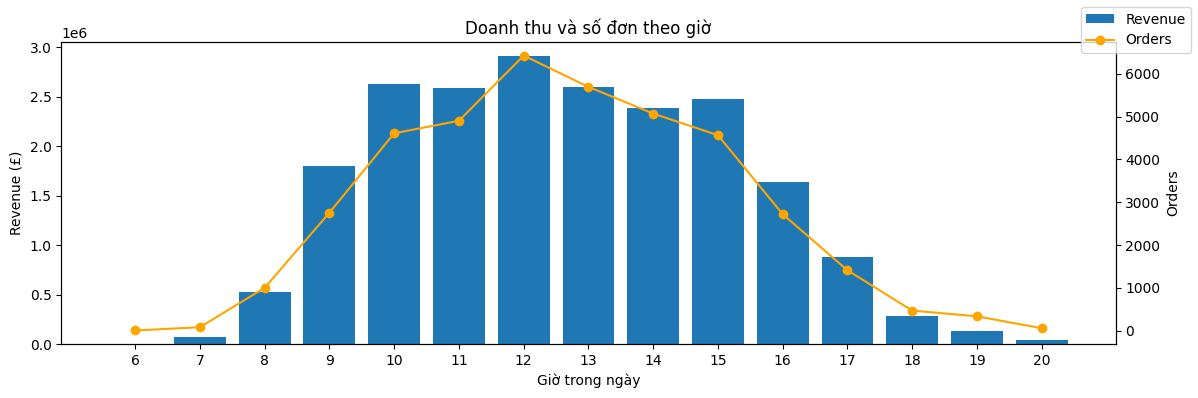

In [ ]:
# Phân tích doanh thu theo giờ
hourly = (sales.groupBy('Hour')
    .agg(
        F.round(F.sum('Revenue'), 2).alias('Revenue'),
        F.countDistinct('InvoiceNo').alias('Orders'),
        F.sum('Quantity').alias('Units'),
        F.countDistinct('Date').alias('ActiveDays')
    )
    .withColumn('AOV', F.round(F.col('Revenue') / F.col('Orders'), 2))
    .withColumn('RevPerDay', F.round(F.col('Revenue') / F.col('ActiveDays'), 2))
    .withColumn('RevShare_%', F.round(F.col('Revenue') / F.lit(revenue) * 100, 2))
    .orderBy('Hour'))

hourly.show(24, truncate=False)
import matplotlib.pyplot as plt

hourly_pd = hourly.toPandas()

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.bar(hourly_pd['Hour'], hourly_pd['Revenue'], label='Revenue')
ax1.set_xlabel('Giờ trong ngày'); ax1.set_ylabel('Revenue (£)')
ax1.set_xticks(hourly_pd['Hour'])

ax2 = ax1.twinx()                                   # trục phụ cho số đơn
ax2.plot(hourly_pd['Hour'], hourly_pd['Orders'], color='orange', marker='o', label='Orders')
ax2.set_ylabel('Orders')

plt.title('Doanh thu và số đơn theo giờ')
fig.legend(loc='upper right'); plt.tight_layout(); plt.show()

#### 3.4. Nhận xét mùa vụ và cao điểm

**a) Mùa vụ theo tháng (bảng `monthly`, mục 5)**
- Doanh thu có tính mùa vụ rõ rệt và lặp lại ở cả hai năm. Giai đoạn **tháng 9–11** chỉ chiếm 6/25 tháng (24% thời gian) nhưng tạo ra **£7.283.155**, tức **34,7% tổng doanh thu**.
- **Tháng 11 là đỉnh mỗi năm**: £1.470.272 (2010) và £1.509.496 (2011), gấp khoảng **2,7–2,9 lần** tháng 2 cùng năm. Doanh thu bắt đầu tăng mạnh từ tháng 9, tăng **+32,6%** (2010) và **+39,4%** (2011) so với tháng 8.
- Cao điểm đến chủ yếu từ **số đơn tăng**, không phải đơn lớn hơn: tháng 11/2011 có **2.769 đơn**, gần gấp đôi mức trung bình khoảng 1.458 đơn/tháng của tháng 3–8/2011, trong khi AOV (£545) gần với các tháng thường.
- **Thấp điểm là tháng 1–2**: tháng 2/2011 đạt £523.632, thấp nhất năm 2011; tháng 1/2011 giảm **53%** so với đỉnh tháng 11/2010. Mùa cao điểm năm sau tốt hơn năm trước khoảng **+4,6%** (tháng 9–11: £3.560.089 → £3.723.066).

**b) Ngày cao điểm (Bảng 3.1)**
- **9/10 ngày** doanh thu cao nhất rơi vào **tháng 9–12**, trong đó 7 ngày thuộc tháng 11–12. **7/10 ngày là thứ 2 hoặc thứ 3**, cho thấy khách thường đặt hàng lớn vào đầu tuần.
- Ngày cao nhất (09/12/2011) đạt **£200.938,6**, gấp khoảng **5,8 lần** doanh thu trung bình một ngày hoạt động (£20.972.594,57 / 604 ngày = £34.723).
- Hai ngày trong top 10 bị chi phối bởi **một dòng giao dịch đơn lẻ**: ngày 09/12/2011 có dòng `PAPER CRAFT , LITTLE BIRDIE` 80.995 × £2,08 = £168.469,6 (**83,8%** doanh thu ngày); ngày 18/01/2011 có dòng `MEDIUM CERAMIC TOP STORAGE JAR` 74.215 × £1,04 = £77.183,6 (**80,4%**). AOV của hai ngày này (£4.566,79 và £2.340,93) cao gấp nhiều lần mức chung £523,31, nên đây là **ngoại lai**, không phản ánh mùa vụ.
- Bốn ngày đầu tháng 12/2010 cùng lọt top 10. Đây là giai đoạn có thể bị trùng khi gộp hai sheet (kết quả kiểm tra cho thấy `sales_clean` có **33.757 dòng trùng hoàn toàn**, 3,2%), nên cần bỏ trùng trước khi kết luận.

**c) Cao điểm theo thứ trong tuần (Bảng 3.2, Hình 3.1)**
- Thứ 2 đến thứ 6 chiếm **91,1%** doanh thu. **Thứ 5** cao nhất: £4.306.392 (20,5%), 80,5 đơn/ngày và **£41.810/ngày**. Thứ 3 đứng thứ hai (£40.249/ngày) với AOV cao nhất tuần (£574,11). Thứ 6 thấp nhất trong các ngày làm việc (£34.111/ngày, thấp hơn thứ 5 khoảng 18%).
- **Chủ nhật** chỉ chiếm 8,8% doanh thu, đạt £18.657/ngày (khoảng **49%** mức trung bình ngày làm việc) và có AOV thấp nhất (£382,01), tức đơn cuối tuần nhỏ hơn.
- **Thứ 7 gần như không hoạt động**: chỉ 1 ngày có giao dịch, 30 đơn, £9.803 (0,05%).

**d) Cao điểm theo giờ (Bảng 3.3, Hình 3.2)**
- Giao dịch diễn ra từ 6h đến 20h, nhưng **8h–17h chiếm 97,5%** doanh thu. Riêng khung **10h–15h chiếm 74,3%**.
- **12h là giờ cao điểm**: £2.910.225 (13,9%) và 6.427 đơn, nhiều nhất trong ngày, nhưng AOV chỉ £452,81. Ngược lại, đơn buổi sáng lớn hơn (9h có AOV £654,39). Sau 18h doanh thu chỉ còn **2,2%**.

**e) Kết luận và hàm ý kinh doanh**
- Nhịp bán hàng theo **giờ hành chính, ngày làm việc, và tập trung vào quý 4**, phù hợp với mô hình bán sỉ cho doanh nghiệp nhập hàng trước mùa lễ cuối năm.
- Doanh nghiệp nên chuẩn bị tồn kho, nhân sự và chiến dịch marketing từ **tháng 8**; dùng tháng 1–2 để kích cầu hoặc xả hàng tồn.
- Trong tuần, nên ưu tiên gửi email marketing và chương trình khuyến mãi **sáng thứ 2–thứ 3** (trước 10h); tăng nhân sự chăm sóc khách hàng khung **10h–15h**; bảo trì hệ thống vào **thứ 7 hoặc sau 18h**.
- **Hạn chế:** kết quả còn chịu ảnh hưởng của dòng trùng, giao dịch ngoại lai và mã phí/dịch vụ (`M`, `DOT`, `POST`…); tháng 12/2011 có số đơn thấp nhất (819), nhiều khả năng dữ liệu không phủ hết tháng.

## 6. Phân tích sản phẩm

In [ ]:
product_sales = (sales.groupBy('StockCode','Description')
    .agg(
        F.sum('Revenue').alias('Revenue'),
        F.sum('Quantity').alias('Units'),
        F.countDistinct('InvoiceNo').alias('Orders')
    ))
product_sales.orderBy(F.desc('Revenue')).show(20, truncate=False)

+---------+-----------------------------------+------------------+-----+------+
|StockCode|Description                        |Revenue           |Units|Orders|
+---------+-----------------------------------+------------------+-----+------+
|22423    |REGENCY CAKESTAND 3 TIER           |344563.25000000064|27577|3918  |
|M        |Manual                             |340716.28000000026|10050|784   |
|DOT      |DOTCOM POSTAGE                     |322657.4800000002 |1436 |1415  |
|85123A   |WHITE HANGING HEART T-LIGHT HOLDER |262931.1599999977 |96086|5356  |
|23843    |PAPER CRAFT , LITTLE BIRDIE        |168469.6          |80995|1     |
|47566    |PARTY BUNTING                      |149187.05000000075|28378|2674  |
|85099B   |JUMBO BAG RED RETROSPOT            |148823.9200000017 |78860|3245  |
|84879    |ASSORTED COLOUR BIRD ORNAMENT      |132187.91999999864|81809|2807  |
|POST     |POSTAGE                            |127597.42         |5461 |1851  |
|22086    |PAPER CHAIN KIT 50'S CHRISTMA

### Bài tập 4
1. Top 20 theo Revenue.
2. Top 20 theo Units.
3. Top 20 theo Orders.
4. Tính tỷ trọng doanh thu Top 10/20/100.
5. Sản phẩm nào có Revenue cao nhưng Units không cao? Vì sao?

1. Top 20 theo Revenue

Tổng doanh thu sản phẩm (đã loại mã phí/dịch vụ): £20,108,995.40
Bảng 4.1. Top 20 sản phẩm theo doanh thu (£)
+---------+-----------------------------------+---------+-----+------+--------+----------+
|StockCode|Description                        |Revenue  |Units|Orders|AvgPrice|RevShare_%|
+---------+-----------------------------------+---------+-----+------+--------+----------+
|22423    |REGENCY CAKESTAND 3 TIER           |344563.25|27577|3918  |12.49   |1.71      |
|85123A   |WHITE HANGING HEART T-LIGHT HOLDER |263109.67|96147|5365  |2.74    |1.31      |
|85099B   |RED RETROSPOT JUMBO BAG            |183454.83|98349|3989  |1.87    |0.91      |
|23843    |PAPER CRAFT , LITTLE BIRDIE        |168469.6 |80995|1     |2.08    |0.84      |
|47566    |PARTY BUNTING                      |149187.05|28378|2674  |5.26    |0.74      |
|84879    |ASSORTED COLOUR BIRD ORNAMENT      |132187.92|81809|2807  |1.62    |0.66      |
|22086    |PAPER CHAIN KIT 50'S CHRISTMAS     |123141.54|36581|2018  |3

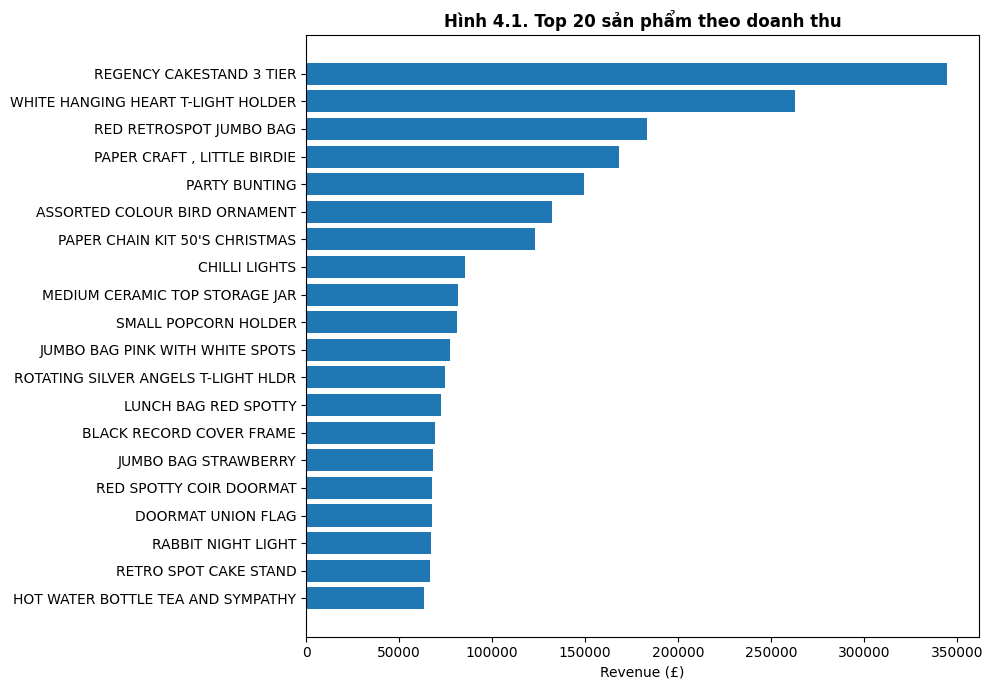

In [ ]:
# Chỉ giữ mã sản phẩm thật: StockCode bắt đầu bằng 5 chữ số (loại M, DOT, POST, AMAZONFEE, ADJUST, gift_...)
is_product = F.col('StockCode').rlike('^[0-9]{5}')

product_clean = (sales
    .filter(is_product)
    .withColumn('Description', F.trim('Description'))
    .groupBy('StockCode')
    .agg(
        F.max('Description').alias('Description'),          # lấy một tên đại diện cho mỗi mã
        F.round(F.sum('Revenue'), 2).alias('Revenue'),
        F.sum('Quantity').alias('Units'),
        F.countDistinct('InvoiceNo').alias('Orders')
    )
    .withColumn('AvgPrice', F.round(F.col('Revenue') / F.col('Units'), 2)))   # giá bình quân / sản phẩm

total_product_rev = product_clean.agg(F.sum('Revenue')).first()[0]

top20_revenue = (product_clean
    .withColumn('RevShare_%', F.round(F.col('Revenue') / F.lit(total_product_rev) * 100, 2))
    .orderBy(F.desc('Revenue'))
    .limit(20))

print(f'Tổng doanh thu sản phẩm (đã loại mã phí/dịch vụ): £{total_product_rev:,.2f}')
print('Bảng 4.1. Top 20 sản phẩm theo doanh thu (£)')
top20_revenue.show(20, truncate=False)
top20_pd = top20_revenue.toPandas().iloc[::-1]       # đảo ngược để sản phẩm lớn nhất nằm trên cùng

plt.figure(figsize=(10, 7))
plt.barh(top20_pd['Description'], top20_pd['Revenue'])
plt.xlabel('Revenue (£)')
plt.title('Hình 4.1. Top 20 sản phẩm theo doanh thu', fontweight='bold')
plt.tight_layout(); plt.show()

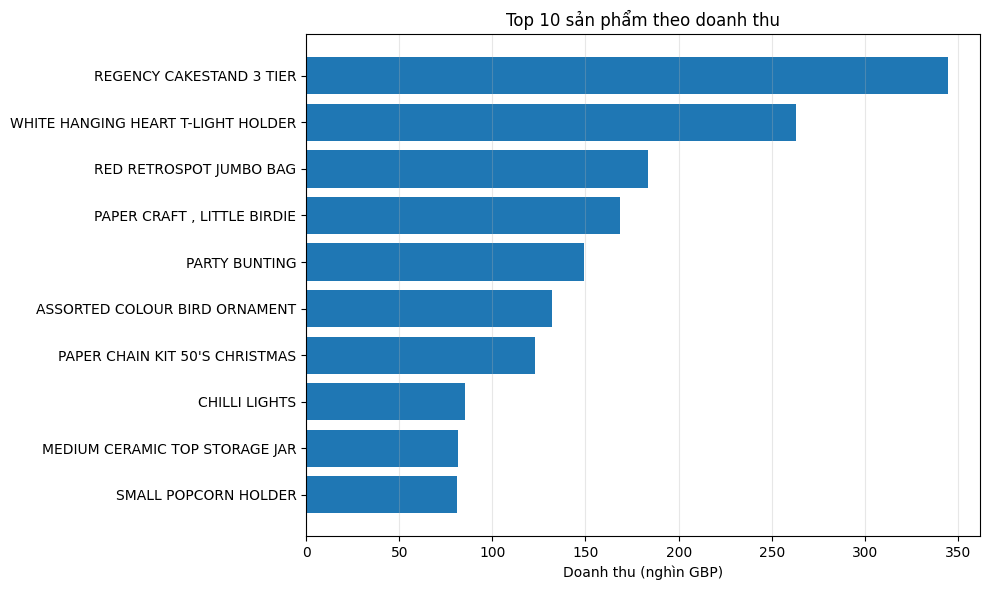

In [ ]:
import matplotlib.pyplot as plt

# Lấy Top 10 sản phẩm theo doanh thu
top10_pd = (
    product_clean
    .orderBy(F.desc('Revenue'))
    .limit(10)
    .toPandas()
    .sort_values('Revenue', ascending=True)
)

# Vẽ biểu đồ
plt.figure(figsize=(10, 6))
plt.barh(
    top10_pd['Description'],
    top10_pd['Revenue'] / 1000
)

plt.title('Top 10 sản phẩm theo doanh thu')
plt.xlabel('Doanh thu (nghìn GBP)')
plt.ylabel('')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

2. Top 20 theo Units.

Tổng số lượng sản phẩm bán ra (đã loại mã phí/dịch vụ): 11,402,383
Bảng 4.2. Top 20 sản phẩm theo số lượng bán (Units)
+---------+-----------------------------------+------+------------+------+-------------+---------+--------+
|StockCode|Description                        |Units |UnitsShare_%|Orders|UnitsPerOrder|Revenue  |AvgPrice|
+---------+-----------------------------------+------+------------+------+-------------+---------+--------+
|84077    |WORLD WAR 2 GLIDERS ASSTD DESIGNS  |110138|0.97        |1019  |108.1        |25259.9  |0.23    |
|85099B   |RED RETROSPOT JUMBO BAG            |98349 |0.86        |3989  |24.7         |183454.83|1.87    |
|21212    |PACK OF 72 RETROSPOT CAKE CASES    |96560 |0.85        |3118  |31.0         |52997.2  |0.55    |
|85123A   |WHITE HANGING HEART T-LIGHT HOLDER |96147 |0.84        |5365  |17.9         |263109.67|2.74    |
|22197    |SMALL POPCORN HOLDER               |89898 |0.79        |2322  |38.7         |80920.64 |0.9     |
|84879    |ASSORT

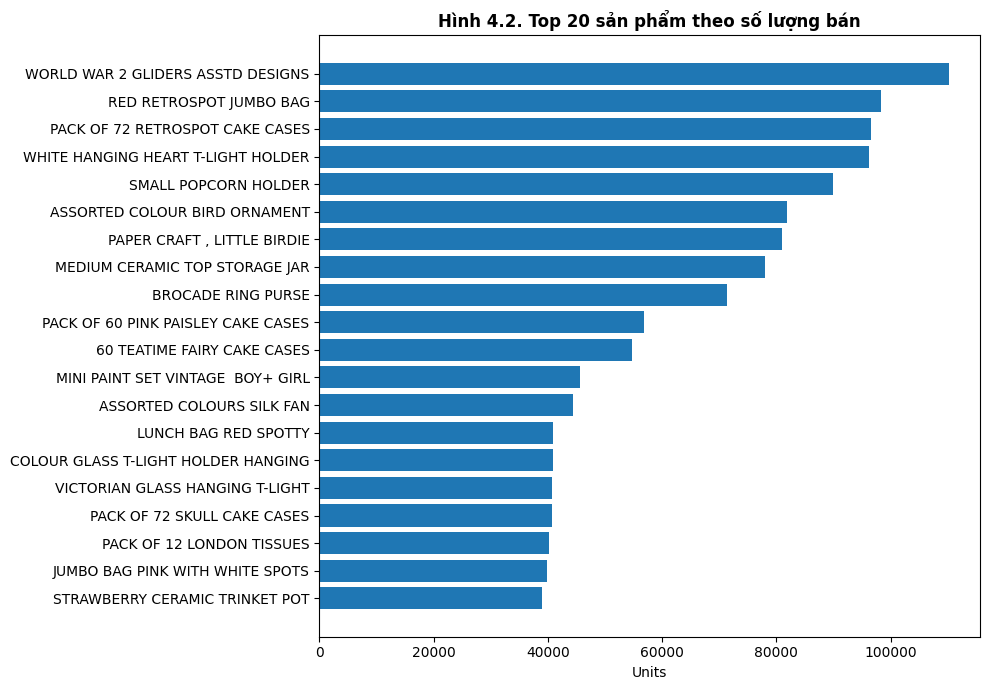

In [ ]:
total_product_units = product_clean.agg(F.sum('Units')).first()[0]

top20_units = (product_clean
    .withColumn('UnitsShare_%', F.round(F.col('Units') / F.lit(total_product_units) * 100, 2))
    .withColumn('UnitsPerOrder', F.round(F.col('Units') / F.col('Orders'), 1))   # số lượng TB mỗi đơn
    .orderBy(F.desc('Units'))
    .limit(20)
    .select('StockCode', 'Description', 'Units', 'UnitsShare_%', 'Orders',
            'UnitsPerOrder', 'Revenue', 'AvgPrice'))

print(f'Tổng số lượng sản phẩm bán ra (đã loại mã phí/dịch vụ): {total_product_units:,}')
print('Bảng 4.2. Top 20 sản phẩm theo số lượng bán (Units)')
top20_units.show(20, truncate=False)
top20u_pd = top20_units.toPandas().iloc[::-1]

plt.figure(figsize=(10, 7))
plt.barh(top20u_pd['Description'], top20u_pd['Units'])
plt.xlabel('Units')
plt.title('Hình 4.2. Top 20 sản phẩm theo số lượng bán', fontweight='bold')
plt.tight_layout(); plt.show()

3. Top 20 theo Orders.

Tổng số hóa đơn có sản phẩm thật: 39,516
Bảng 4.3. Top 20 sản phẩm theo số đơn hàng (Orders)
+---------+----------------------------------+------+-------------+-----+-------------+---------+--------+
|StockCode|Description                       |Orders|Penetration_%|Units|UnitsPerOrder|Revenue  |AvgPrice|
+---------+----------------------------------+------+-------------+-----+-------------+---------+--------+
|85123A   |WHITE HANGING HEART T-LIGHT HOLDER|5365  |13.58        |96147|17.9         |263109.67|2.74    |
|85099B   |RED RETROSPOT JUMBO BAG           |3989  |10.09        |98349|24.7         |183454.83|1.87    |
|22423    |REGENCY CAKESTAND 3 TIER          |3918  |9.91         |27577|7.0          |344563.25|12.49   |
|21212    |PACK OF 72 RETROSPOT CAKE CASES   |3118  |7.89         |96560|31.0         |52997.2  |0.55    |
|20725    |LUNCH BAG RED SPOTTY              |3056  |7.73         |40942|13.4         |72292.85 |1.77    |
|84879    |ASSORTED COLOUR BIRD ORNAMENT     |2807 

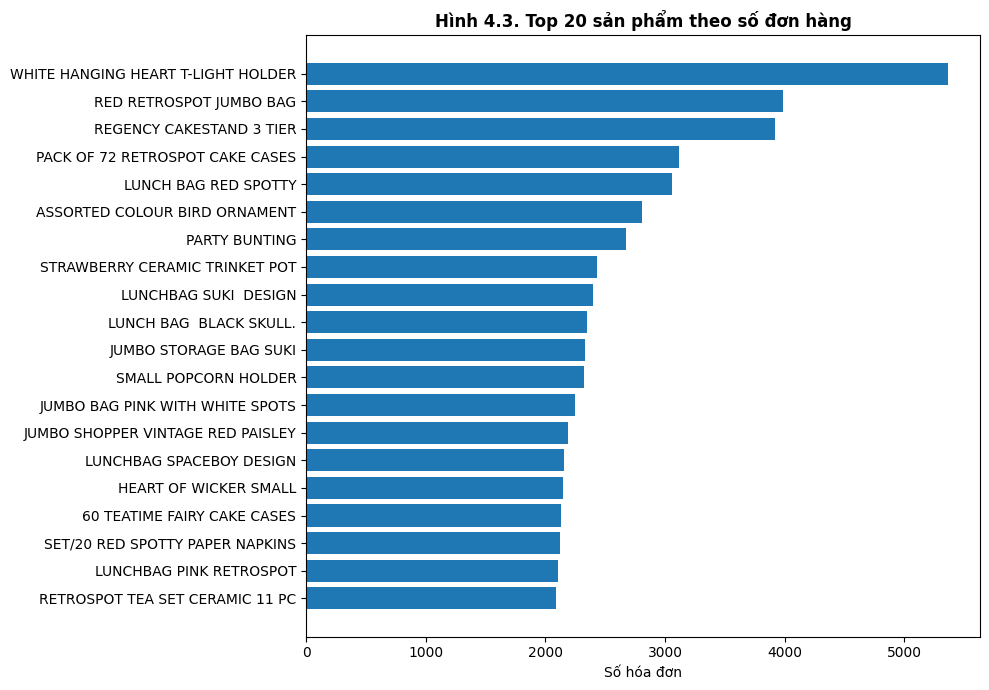

In [ ]:
total_product_orders = (sales.filter(is_product)
                             .agg(F.countDistinct('InvoiceNo')).first()[0])

top20_orders = (product_clean
    .withColumn('Penetration_%', F.round(F.col('Orders') / F.lit(total_product_orders) * 100, 2))
    .withColumn('UnitsPerOrder', F.round(F.col('Units') / F.col('Orders'), 1))
    .orderBy(F.desc('Orders'))
    .limit(20)
    .select('StockCode', 'Description', 'Orders', 'Penetration_%', 'Units',
            'UnitsPerOrder', 'Revenue', 'AvgPrice'))

print(f'Tổng số hóa đơn có sản phẩm thật: {total_product_orders:,}')
print('Bảng 4.3. Top 20 sản phẩm theo số đơn hàng (Orders)')
top20_orders.show(20, truncate=False)
top20o_pd = top20_orders.toPandas().iloc[::-1]

plt.figure(figsize=(10, 7))
plt.barh(top20o_pd['Description'], top20o_pd['Orders'])
plt.xlabel('Số hóa đơn')
plt.title('Hình 4.3. Top 20 sản phẩm theo số đơn hàng', fontweight='bold')
plt.tight_layout(); plt.show()

4. Tỷ trọng doanh thu Top 10/20/100

In [ ]:
w_rank = Window.orderBy(F.desc('Revenue'))
ranked = product_clean.withColumn('Rank', F.row_number().over(w_rank))

n_products = product_clean.count()

share = ranked.agg(*[
    F.round(F.sum(F.when(F.col('Rank') <= n, F.col('Revenue'))), 2).alias(f'Top{n}')
    for n in [10, 20, 100]
]).first()

rows = [(f'Top {n}', n, round(n / n_products * 100, 2),
         float(share[f'Top{n}']), round(share[f'Top{n}'] / total_product_rev * 100, 2))
        for n in [10, 20, 100]]

share_df = spark.createDataFrame(rows, ['Group', 'Products', 'ProductShare_%', 'Revenue', 'RevShare_%'])

print(f'Tổng số sản phẩm: {n_products:,} | Tổng doanh thu sản phẩm: £{total_product_rev:,.2f}')
print('Bảng 4.4. Tỷ trọng doanh thu của Top 10/20/100 sản phẩm')
share_df.show(truncate=False)

Tổng số sản phẩm: 4,878 | Tổng doanh thu sản phẩm: £20,108,995.40
Bảng 4.4. Tỷ trọng doanh thu của Top 10/20/100 sản phẩm
+-------+--------+--------------+----------+----------+
|Group  |Products|ProductShare_%|Revenue   |RevShare_%|
+-------+--------+--------------+----------+----------+
|Top 10 |10      |0.21          |1612225.33|8.02      |
|Top 20 |20      |0.41          |2306617.42|11.47     |
|Top 100|100     |2.05          |5918824.34|29.43     |
+-------+--------+--------------+----------+----------+



Nhận xét: Tỷ trọng doanh thu Top 10/20/100

- Top 10 sản phẩm (0,21% số mã) tạo ra £1.612.225,33, tức 8,02% doanh thu sản phẩm. Mỗi sản phẩm trong nhóm này mang lại doanh thu gấp khoảng 38 lần mức trung bình (8,02 / 0,21).

- Top 20 (0,41% số mã) chiếm 11,47%. Nhóm hạng 11–20 chỉ bổ sung thêm £694.392,09 (khoảng 3,45 điểm %), nên doanh thu giảm khá nhanh sau nhóm đầu bảng.

- Top 100 (2,05% số mã) chiếm 29,43% (£5.918.824,34). Nghĩa là gần 98% số mã còn lại tạo ra khoảng 70,6% doanh thu.

- Kết luận: doanh thu có tập trung nhưng ở mức vừa phải. Một nhóm nhỏ khoảng 2% sản phẩm đóng góp gần 1/3 doanh thu, nhưng phần lớn doanh thu vẫn đến từ danh mục dài với hàng nghìn mã, mỗi mã đóng góp nhỏ. Doanh nghiệp không phụ thuộc vào vài sản phẩm chủ lực. Ngược lại, điều này cho thấy chi phí quản lý tồn kho cho số lượng mã lớn có thể là thách thức.

- Lưu ý: khoảng 1,25 điểm % trong tỷ trọng Top 10 đến từ hai sản phẩm ngoại lai PAPER CRAFT , LITTLE BIRDIE (0,84%) và MEDIUM CERAMIC TOP STORAGE JAR (0,41%). Nếu loại hai giao dịch bất thường này, mức tập trung thực tế còn thấp hơn.

5. Sản phẩm nào có Revenue cao nhưng Units không cao? Vì sao?

| Sản phẩm | Revenue | Units | AvgPrice |
| :--- | :--- | :--- | :--- |
| REGENCY CAKESTAND 3 TIER | £344.563,25 (hạng 1) | 27.577 | £12,49 |
| RETRO SPOT CAKE STAND | £66.620,20 | 6.290 | £10,59 |
| RED SPOTTY COIR DOORMAT | £67.859,56 | 9.974 | £6,80 |
| DOORMAT UNION FLAG | £67.757,63 | 10.175 | £6,66 |
| PARTY BUNTING | £149.187,05 | 28.378 | £5,26 |
| HOT WATER BOTTLE TEA AND SYMPATHY | £63.517,75 | 12.462 | £5,10 |
| CHILLI LIGHTS | £85.489,91 | 16.840 | £5,08 |

Lý do: các sản phẩm này có giá bình quân cao (£5–12,5/sản phẩm), trong khi phần lớn top 20 số lượng có giá dưới £2. Ví dụ, REGENCY CAKESTAND 3 TIER chỉ bán khoảng 1/3 số lượng của WHITE HANGING HEART T-LIGHT HOLDER (27.577 so với 96.147), nhưng giá cao gấp khoảng 4,6 lần (£12,49 so với £2,74), nên vẫn dẫn đầu doanh thu.

Đây là các mặt hàng giá trị cao, bán theo số lượng vừa phải như bánh kem tầng, thảm chùi chân, đồ trang trí. Chúng thường được mua ít mỗi đơn (REGENCY CAKESTAND chỉ 7,0 sp/đơn theo Bảng 4.3, so với 17,9 của WHITE HANGING HEART). Nhóm này phù hợp để làm sản phẩm nâng giá trị đơn hàng (upsell).


## 7. Phân tích thị trường theo quốc gia

In [ ]:
country_sales = (sales.groupBy('Country')
    .agg(
        F.sum('Revenue').alias('Revenue'),
        F.countDistinct('InvoiceNo').alias('Orders'),
        F.countDistinct('CustomerID').alias('Customers')
    )
    .withColumn('AOV', F.col('Revenue')/F.col('Orders'))
    .orderBy(F.desc('Revenue')))
country_sales.show(20, truncate=False)

+---------------+--------------------+------+---------+------------------+
|Country        |Revenue             |Orders|Customers|AOV               |
+---------------+--------------------+------+---------+------------------+
|United Kingdom |1.7870977777004868E7|36535 |5350     |489.14678464499434|
|EIRE           |664431.7800000075   |626   |5        |1061.3926198083186|
|Netherlands    |554232.3400000011   |228   |22       |2430.8435964912333|
|Germany        |431262.46099999954  |789   |107      |546.5937401774393 |
|France         |356944.5999999994   |622   |95       |573.8659163987129 |
|Australia      |169968.1099999996   |95    |15       |1789.1379999999958|
|Spain          |109178.53000000006  |154   |41       |708.9514935064939 |
|Switzerland    |101011.29000000015  |93    |22       |1086.1429032258081|
|Sweden         |91903.71999999986   |105   |19       |875.2735238095224 |
|Denmark        |69862.19            |43    |12       |1624.7020930232559|
|Belgium        |65753.42

### Bài tập 5
- Top 10 quốc gia ngoài UK theo Revenue.
- So sánh AOV giữa các quốc gia có ≥ 50 orders.
- Thị trường quốc tế nào có tiềm năng nhất theo dữ liệu hiện có?

1. Top 10 quốc gia ngoài UK theo Revenue

In [ ]:
excluded = ['United Kingdom', 'Unspecified']          # 'Unspecified': quốc gia không xác định (nếu có)

intl = country_sales.filter(~F.col('Country').isin(excluded))
intl_rev = intl.agg(F.sum('Revenue')).first()[0]

top10_intl = (intl
    .withColumn('RevShare_%',  F.round(F.col('Revenue') / F.lit(revenue)  * 100, 2))   # % tổng doanh thu
    .withColumn('IntlShare_%', F.round(F.col('Revenue') / F.lit(intl_rev) * 100, 2))   # % doanh thu quốc tế
    .withColumn('Revenue', F.col('Revenue').cast('decimal(18,2)'))
    .withColumn('AOV', F.round('AOV', 2))
    .orderBy(F.desc('Revenue'))
    .limit(10))

print(f'Doanh thu quốc tế (ngoài UK): £{intl_rev:,.2f} ({intl_rev/revenue:.2%} tổng doanh thu)')
print('Bảng 5.1. Top 10 quốc gia ngoài UK theo doanh thu (£)')
top10_intl.show(truncate=False)

Doanh thu quốc tế (ngoài UK): £3,090,680.78 (14.74% tổng doanh thu)
Bảng 5.1. Top 10 quốc gia ngoài UK theo doanh thu (£)
+-----------+---------+------+---------+-------+----------+-----------+
|Country    |Revenue  |Orders|Customers|AOV    |RevShare_%|IntlShare_%|
+-----------+---------+------+---------+-------+----------+-----------+
|EIRE       |664431.78|626   |5        |1061.39|3.17      |21.5       |
|Netherlands|554232.34|228   |22       |2430.84|2.64      |17.93      |
|Germany    |431262.46|789   |107      |546.59 |2.06      |13.95      |
|France     |356944.60|622   |95       |573.87 |1.7       |11.55      |
|Australia  |169968.11|95    |15       |1789.14|0.81      |5.5        |
|Spain      |109178.53|154   |41       |708.95 |0.52      |3.53       |
|Switzerland|101011.29|93    |22       |1086.14|0.48      |3.27       |
|Sweden     |91903.72 |105   |19       |875.27 |0.44      |2.97       |
|Denmark    |69862.19 |43    |12       |1624.7 |0.33      |2.26       |
|Belgium    |6

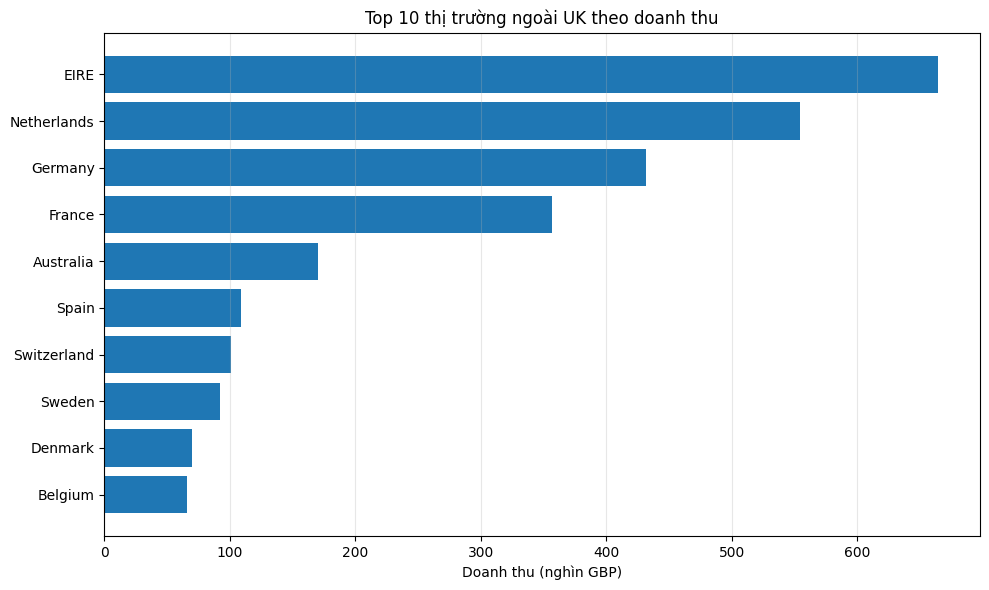

In [56]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# Tính doanh thu theo quốc gia, loại UK
country_revenue = (
    sales_clean
    .filter(F.col("Country") != "United Kingdom")
    .groupBy("Country")
    .agg(
        F.round(F.sum(F.col("Quantity") * F.col("UnitPrice")), 2)
        .alias("Revenue")
    )
    .orderBy(F.desc("Revenue"))
)

# Lấy Top 10 quốc gia
top10_country_pd = (
    country_revenue
    .limit(10)
    .toPandas()
    .sort_values("Revenue", ascending=True)
)

# Vẽ biểu đồ
plt.figure(figsize=(10, 6))
plt.barh(
    top10_country_pd["Country"],
    top10_country_pd["Revenue"] / 1000
)

plt.title("Top 10 thị trường ngoài UK theo doanh thu")
plt.xlabel("Doanh thu (nghìn GBP)")
plt.ylabel("")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

2. So sánh AOV giữa các quốc gia có ≥ 50 đơn

Số quốc gia có ≥ 50 đơn: 14 | AOV của UK: £489.15
Bảng 5.2. AOV của các quốc gia có từ 50 đơn hàng trở lên (£)
+---------------+-----------+------+---------+-------+---------+--------------+
|Country        |Revenue    |Orders|Customers|AOV    |AOV_vs_UK|RevPerCustomer|
+---------------+-----------+------+---------+-------+---------+--------------+
|Netherlands    |554232.34  |228   |22       |2430.84|4.97     |25192.38      |
|Australia      |169968.11  |95    |15       |1789.14|3.66     |11331.21      |
|Switzerland    |101011.29  |93    |22       |1086.14|2.22     |4591.42       |
|EIRE           |664431.78  |626   |5        |1061.39|2.17     |132886.36     |
|Sweden         |91903.72   |105   |19       |875.27 |1.79     |4837.04       |
|Channel Islands|44996.76   |55    |13       |818.12 |1.67     |3461.29       |
|Spain          |109178.53  |154   |41       |708.95 |1.45     |2662.89       |
|Portugal       |58016.65   |95    |24       |610.7  |1.25     |2417.36       |
|France  

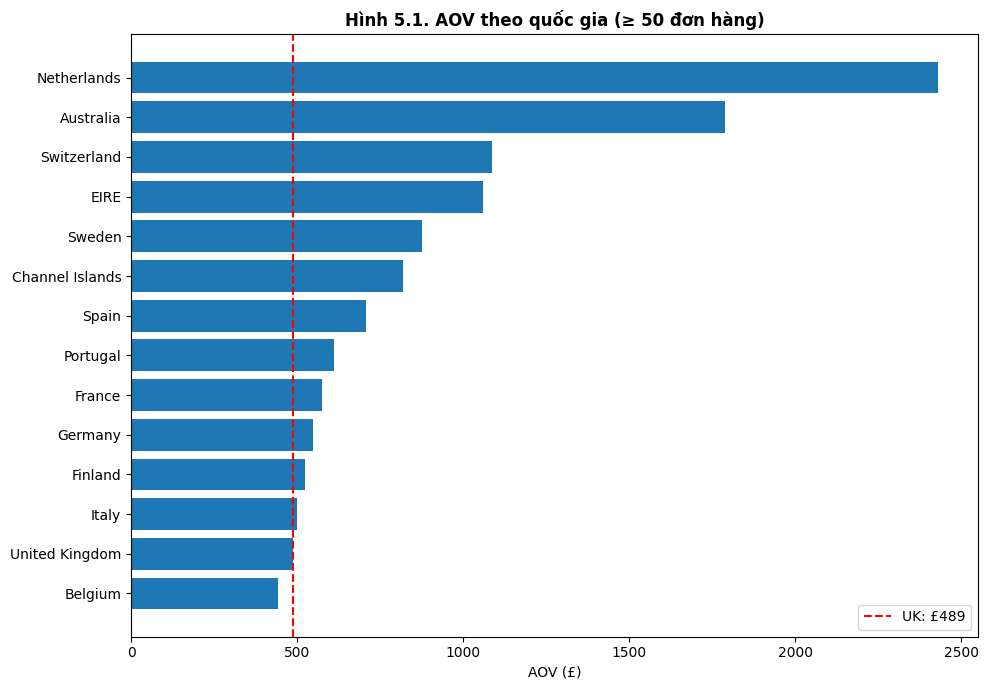

In [ ]:
uk_aov = country_sales.filter(F.col('Country') == 'United Kingdom').first()['AOV']

aov_compare = (country_sales
    .filter((F.col('Orders') >= 50) & (F.col('Country') != 'Unspecified'))
    .withColumn('AOV', F.round('AOV', 2))
    .withColumn('AOV_vs_UK', F.round(F.col('AOV') / F.lit(uk_aov), 2))     # 1.5 = cao hơn UK 50%
    .withColumn('RevPerCustomer', F.round(F.col('Revenue') / F.col('Customers'), 2))
    .withColumn('Revenue', F.col('Revenue').cast('decimal(18,2)'))
    .orderBy(F.desc('AOV')))

print(f'Số quốc gia có ≥ 50 đơn: {aov_compare.count()} | AOV của UK: £{uk_aov:,.2f}')
print('Bảng 5.2. AOV của các quốc gia có từ 50 đơn hàng trở lên (£)')
aov_compare.show(50, truncate=False)

# Hình 5.1
aov_pd = aov_compare.toPandas().iloc[::-1]
plt.figure(figsize=(10, 7))
plt.barh(aov_pd['Country'], aov_pd['AOV'])
plt.axvline(uk_aov, color='red', linestyle='--', label=f'UK: £{uk_aov:,.0f}')
plt.xlabel('AOV (£)'); plt.legend()
plt.title('Hình 5.1. AOV theo quốc gia (≥ 50 đơn hàng)', fontweight='bold')
plt.tight_layout(); plt.show()

3. Thị trường quốc tế nào tiềm năng nhất?

In [ ]:
# (a) Chỉ số quy mô và tăng trưởng theo quốc gia
P1 = (F.col('InvoiceDate') >= '2009-12-01') & (F.col('InvoiceDate') < '2010-12-01')
P2 = (F.col('InvoiceDate') >= '2010-12-01') & (F.col('InvoiceDate') < '2011-12-01')

country_detail = (sales
    .filter(~F.col('Country').isin(excluded))
    .groupBy('Country')
    .agg(
        F.sum('Revenue').alias('Revenue'),
        F.countDistinct('InvoiceNo').alias('Orders'),
        F.countDistinct('CustomerID').alias('Customers'),
        F.sum(F.when(P1, F.col('Revenue'))).alias('Rev_P1'),
        F.sum(F.when(P2, F.col('Revenue'))).alias('Rev_P2'))
    .filter(F.col('Orders') >= 50)
    .withColumn('AOV', F.col('Revenue') / F.col('Orders'))
    .withColumn('Growth_%', (F.col('Rev_P2') / F.col('Rev_P1') - 1) * 100))

# (b) Mức phụ thuộc vào khách lớn nhất trong từng nước
cust_country = (sales.filter(F.col('CustomerID').isNotNull())
    .groupBy('Country', 'CustomerID')
    .agg(F.sum('Revenue').alias('CustRev')))

top_cust = (cust_country.groupBy('Country')
    .agg((F.max('CustRev') / F.sum('CustRev') * 100).alias('TopCustShare_%')))

# (c) Chấm điểm: percent_rank đưa mỗi tiêu chí về thang 0–1, rồi lấy trung bình
def pr(col, ascending=False):
    order = F.col(col).asc() if ascending else F.col(col).desc()
    return 1 - F.percent_rank().over(Window.orderBy(order))   # 1 = tốt nhất

potential = (country_detail.join(top_cust, 'Country', 'left')
    .withColumn('S_Revenue',   pr('Revenue'))
    .withColumn('S_Growth',    pr('Growth_%'))
    .withColumn('S_Customers', pr('Customers'))
    .withColumn('S_AOV',       pr('AOV'))
    .withColumn('S_Risk',      pr('TopCustShare_%', ascending=True))   # phụ thuộc càng thấp càng tốt
    .withColumn('Score', F.round((F.col('S_Revenue') + F.col('S_Growth') + F.col('S_Customers')
                                  + F.col('S_AOV') + F.col('S_Risk')) / 5 * 100, 1))
    .select('Country',
            F.col('Revenue').cast('decimal(18,2)').alias('Revenue'),
            'Orders', 'Customers',
            F.round('AOV', 2).alias('AOV'),
            F.round('Growth_%', 1).alias('Growth_%'),
            F.round('TopCustShare_%', 1).alias('TopCustShare_%'),
            'Score')
    .orderBy(F.desc('Score')))

print('Bảng 5.3. Đánh giá tiềm năng thị trường quốc tế (≥ 50 đơn, điểm 0–100)')
potential.show(50, truncate=False)

Bảng 5.3. Đánh giá tiềm năng thị trường quốc tế (≥ 50 đơn, điểm 0–100)
+---------------+---------+------+---------+-------+--------+--------------+-----+
|Country        |Revenue  |Orders|Customers|AOV    |Growth_%|TopCustShare_%|Score|
+---------------+---------+------+---------+-------+--------+--------------+-----+
|France         |356944.60|622   |95       |573.87 |48.1    |9.6           |73.3 |
|Germany        |431262.46|789   |107      |546.59 |15.2    |9.3           |68.3 |
|Spain          |109178.53|154   |41       |708.95 |32.6    |20.4          |61.7 |
|Switzerland    |101011.29|93    |22       |1086.14|31.6    |23.3          |58.3 |
|Australia      |169968.11|95    |15       |1789.14|351.3   |85.0          |58.3 |
|Belgium        |65753.42 |149   |29       |441.3  |65.7    |14.7          |55.0 |
|Netherlands    |554232.34|228   |22       |2430.84|2.0     |95.4          |55.0 |
|Portugal       |58016.65 |95    |24       |610.7  |44.2    |17.6          |53.3 |
|EIRE           

**Nhận xét Bảng 5.1:** Top 10 quốc gia ngoài UK
Doanh nghiệp phụ thuộc rất lớn vào thị trường nội địa. UK tạo ra £17.870.977,78, tức khoảng 85,2% tổng doanh thu. Top 10 quốc gia ngoài UK cộng lại chỉ chiếm 13,26% tổng doanh thu.

Doanh thu quốc tế tập trung ở châu Âu, nhất là 4 nước dẫn đầu: EIRE, Netherlands, Germany và France chiếm khoảng 64,9% doanh thu quốc tế. Ngoài châu Âu, chỉ Australia lọt top 10 (5,5%).

Hai kiểu thị trường rất khác nhau:
- EIRE và Netherlands dẫn đầu doanh thu (£664.432 và £554.232) nhưng chỉ có 5 và 22 khách.
- Germany và France có doanh thu thấp hơn nhưng tệp khách rộng hơn nhiều (107 và 95 khách), đồng thời có số đơn cao nhất ngoài UK (789 và 622 đơn).

**Nhận xét Bảng 5.2:** So sánh AOV (≥ 50 đơn)
Gần như mọi thị trường quốc tế đều có AOV cao hơn UK. 12/13 nước có AOV vượt mức £489,15 của UK. Chỉ Belgium thấp hơn (£441,30). Nhiều khả năng do khách nước ngoài gộp hàng thành đơn lớn hơn để tiết kiệm chi phí vận chuyển.

Netherlands có AOV cao nhất, £2.430,84, gấp 4,97 lần UK. Tiếp theo là Australia (£1.789,14, gấp 3,66 lần) và Switzerland (£1.086,14).

AOV cao đi kèm ít khách. Ba nước AOV cao nhất là Netherlands, Australia và EIRE, đều có từ 22 khách trở xuống. Rõ nhất là EIRE: doanh thu bình quân £132.886/khách, gấp khoảng 40 lần UK (£3.340). Đây là đặc điểm của khách sỉ lớn, không phải một thị trường rộng.

Germany và France có AOV gần với UK (gấp 1,12 và 1,17 lần), tức hành vi mua tương tự thị trường nội địa.

**Nhận xét Bảng 5.3:** Đánh giá tiềm năng

France có điểm cao nhất (73,3). France tăng trưởng mạnh (+48,1%), có 95 khách, và khách lớn nhất chỉ chiếm 9,6% doanh thu, tức rủi ro phụ thuộc thấp.

Germany đứng thứ hai (68,3). Germany có tệp khách lớn nhất (107), nhiều đơn nhất (789), mức phụ thuộc thấp nhất (9,3%) và vẫn tăng trưởng dương (+15,2%).

Spain (61,7) là thị trường mới nổi đáng chú ý: tăng +32,6%, 41 khách, mức phụ thuộc vừa phải (20,4%).

Tăng trưởng cao chưa chắc là tiềm năng:

- Australia tăng +351,3% nhưng một khách chiếm 85% doanh thu, nên tăng trưởng gần như đến từ một khách.
- Finland tăng +188,8% nhưng quy mô rất nhỏ (£29.926).

Doanh thu lớn nhưng rủi ro cao:

- Netherlands: một khách chiếm 95,4% doanh thu, gần như đây là một tài khoản chứ không phải một thị trường, và tăng trưởng chỉ +2,0%.
- EIRE: doanh thu cao nhất ngoài UK nhưng giảm 25,1%, với khách lớn nhất chiếm 50,5%.
- Sweden và Channel Islands cũng giảm (−28,7% và −14,8%).

**Kết luận:** Thị trường quốc tế tiềm năng nhất

France và Germany là hai thị trường tiềm năng nhất. Cả hai hội đủ 3 yếu tố: quy mô đáng kể (lần lượt khoảng £357 nghìn và £431 nghìn), tăng trưởng dương, và tệp khách rộng với mức phụ thuộc vào một khách dưới 10%. Đây là những thị trường có thể mở rộng bằng marketing để thu hút thêm khách mới. Spain là lựa chọn tiếp theo nhờ tốc độ tăng trưởng cao.

Netherlands, EIRE và Australia không nên xem là “thị trường” mà là khách hàng trọng điểm (key accounts). Doanh thu của các nước này phụ thuộc vào 1–2 khách sỉ lớn, nên chiến lược phù hợp là chăm sóc riêng để giữ chân (chiết khấu theo khối lượng, quản lý tài khoản riêng). Riêng EIRE cần tìm hiểu nguyên nhân sụt giảm 25,1%.


## 8. Phân tích khách hàng

In [ ]:
cust = (sales_customer
    .withColumn('Revenue', F.col('Quantity')*F.col('UnitPrice'))
    .groupBy('CustomerID')
    .agg(
        F.sum('Revenue').alias('Revenue'),
        F.countDistinct('InvoiceNo').alias('Orders'),
        F.sum('Quantity').alias('Units')
    )
    .withColumn('AOV', F.col('Revenue')/F.col('Orders')))
cust.orderBy(F.desc('Revenue')).show(20)

+----------+------------------+------+------+------------------+
|CustomerID|           Revenue|Orders| Units|               AOV|
+----------+------------------+------+------+------------------+
|   18102.0| 608821.6499999999|   145|188340|4198.7699999999995|
|   14646.0| 528602.5199999999|   151|367193|3500.6789403973503|
|   14156.0|313946.36999999994|   156|165992|2012.4767307692305|
|   14911.0|295972.63000000006|   398|149987| 743.6498241206032|
|   17450.0|246973.08999999994|    51| 84720|4842.6096078431365|
|   13694.0|         196482.81|   143|189205|1374.0056643356643|
|   17511.0|175603.55000000002|    60|119656|2926.7258333333334|
|   16446.0|          168472.5|     2| 80997|          84236.25|
|   16684.0|         147142.77|    55|104810|2675.3230909090908|
|   12415.0|144458.36999999997|    28| 91447| 5159.227499999999|
|   15061.0|         137818.52|   127| 80711|1085.1851968503936|
|   16029.0|122209.14000000004|   107| 56486|1142.1414953271033|
|   17949.0|         1186

### Bài tập 6. Concentration
Tính tỷ trọng Revenue do Top 1%, 5%, 10% khách hàng tạo ra. Nhận xét mức độ tập trung.

Số khách hàng: 5,878 | Doanh thu từ khách có mã: £17,743,429.18
Doanh thu bình quân mỗi khách (đã sửa): £3,018.62
Bảng 6.1. Doanh thu tích lũy của 10 khách hàng lớn nhất
+----+----------+---------+------+----------+-------------+--------------+
|Rank|CustomerID|Revenue  |Orders|CumRevenue|CumRevShare_%|CumCustShare_%|
+----+----------+---------+------+----------+-------------+--------------+
|1   |18102     |608821.65|145   |608821.65 |3.43         |0.02          |
|2   |14646     |528602.52|151   |1137424.17|6.41         |0.03          |
|3   |14156     |313946.37|156   |1451370.54|8.18         |0.05          |
|4   |14911     |295972.63|398   |1747343.17|9.85         |0.07          |
|5   |17450     |246973.09|51    |1994316.26|11.24        |0.09          |
|6   |13694     |196482.81|143   |2190799.07|12.35        |0.1           |
|7   |17511     |175603.55|60    |2366402.62|13.34        |0.12          |
|8   |16446     |168472.5 |2     |2534875.12|14.29        |0.14          |
|9   

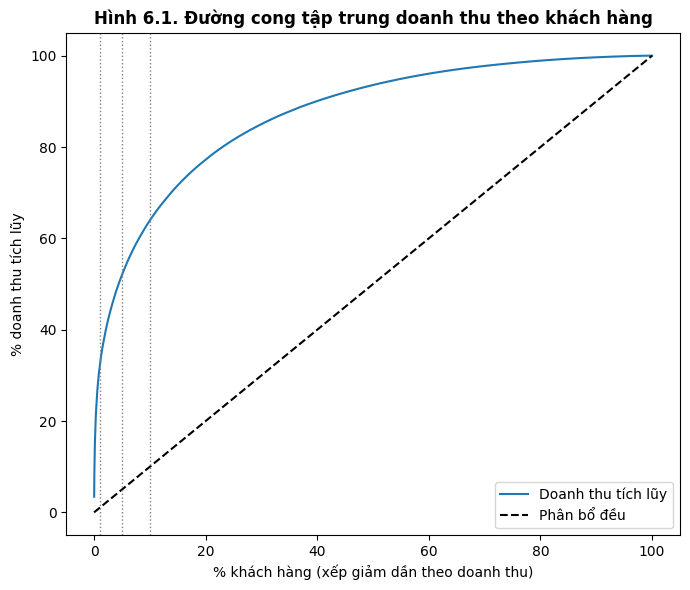

In [ ]:
# TODO: dùng Window để tính cumulative revenue share theo khách hàng
# Tỷ trọng doanh thu tích lũy theo khách hàng
import math

n_cust = cust.count()
total_cust_rev = cust.agg(F.sum('Revenue')).first()[0]

# Window xếp hạng và cộng dồn (thêm CustomerID để thứ tự ổn định khi trùng doanh thu)
w_rank = Window.orderBy(F.desc('Revenue'), F.col('CustomerID'))
w_cum  = w_rank.rowsBetween(Window.unboundedPreceding, Window.currentRow)

cust_cum = (cust
    .withColumn('CustomerID', F.col('CustomerID').cast('int'))
    .withColumn('Rank', F.row_number().over(w_rank))
    .withColumn('CumRevenue', F.sum('Revenue').over(w_cum))
    .withColumn('CumRevShare_%', F.round(F.col('CumRevenue') / F.lit(total_cust_rev) * 100, 2))
    .withColumn('CumCustShare_%', F.round(F.col('Rank') / F.lit(n_cust) * 100, 2))
    .cache())                                   # dùng lại nhiều lần nên lưu vào bộ nhớ

print(f'Số khách hàng: {n_cust:,} | Doanh thu từ khách có mã: £{total_cust_rev:,.2f}')
print(f'Doanh thu bình quân mỗi khách (đã sửa): £{total_cust_rev / n_cust:,.2f}')
print('Bảng 6.1. Doanh thu tích lũy của 10 khách hàng lớn nhất')
cust_cum.select('Rank', 'CustomerID', F.round('Revenue', 2).alias('Revenue'), 'Orders',
                F.round('CumRevenue', 2).alias('CumRevenue'), 'CumRevShare_%', 'CumCustShare_%') \
        .orderBy('Rank').show(10, truncate=False)

# Tỷ trọng doanh thu của Top 1%, 5%, 10%
rows = []
for p in [1, 5, 10, 20]:
    k = math.ceil(n_cust * p / 100)                       # số khách thuộc top p%
    r = cust_cum.filter(F.col('Rank') == k).first()
    rows.append((f'Top {p}%', k, float(round(r['CumRevenue'], 2)), float(r['CumRevShare_%'])))

conc = spark.createDataFrame(rows, ['Group', 'Customers', 'Revenue', 'RevShare_%'])

print('Bảng 6.2. Tỷ trọng doanh thu của Top 1%, 5%, 10%, 20% khách hàng')
conc.show(truncate=False)

# Cần bao nhiêu % khách để đạt 50% và 80% doanh thu?
for target in [50, 80]:
    r = cust_cum.filter(F.col('CumRevShare_%') >= target).orderBy('Rank').first()
    print(f'{target}% doanh thu đến từ {r["Rank"]:,} khách đầu tiên = {r["CumCustShare_%"]}% số khách')

# Biểu đồ đường cong tập trung
cc_pd = cust_cum.select('CumCustShare_%', 'CumRevShare_%').orderBy('CumCustShare_%').toPandas()

plt.figure(figsize=(7, 6))
plt.plot(cc_pd['CumCustShare_%'], cc_pd['CumRevShare_%'], label='Doanh thu tích lũy')
plt.plot([0, 100], [0, 100], 'k--', label='Phân bổ đều')
for p in [1, 5, 10]:
    plt.axvline(p, color='gray', linestyle=':', linewidth=1)
plt.xlabel('% khách hàng (xếp giảm dần theo doanh thu)')
plt.ylabel('% doanh thu tích lũy')
plt.title('Hình 6.1. Đường cong tập trung doanh thu theo khách hàng', fontweight='bold')
plt.legend(); plt.tight_layout(); plt.show()

Nhận xét mức độ tập trung khách hàng:

Doanh thu tập trung rất cao vào một nhóm nhỏ khách hàng.

- Top 1% (59 khách) tạo ra £5.667.105,55, tức 31,94% doanh thu từ khách có mã. Mỗi khách trong nhóm này mang lại trung bình khoảng £96.053.
- Chỉ 259 khách (4,41%) đã tạo ra một nửa doanh thu. Top 5% (294 khách) chiếm 51,99%.

Gần đúng quy luật 80/20. Top 20% khách (1.176 khách) chiếm 77,26% doanh thu. Để đạt đúng 80% doanh thu cần 1.353 khách, tương đương 23,02% số khách. Ngược lại, 80% khách còn lại (4.702 khách) chỉ đóng góp 22,74%.

Chênh lệch giá trị giữa các nhóm rất lớn. Tính theo tỷ trọng, một khách trung bình trong Top 1% mang lại doanh thu gấp khoảng 112 lần một khách trung bình trong nhóm 80% dưới cùng. Mức tăng thêm cũng giảm dần qua từng nhóm:
- Từ Top 1% lên Top 5%: thêm 235 khách, đóng góp +20,05 điểm %.
- Từ Top 5% lên Top 10%: thêm 294 khách, chỉ đóng góp +11,94 điểm %.

Khách hàng tập trung mạnh hơn nhiều so với sản phẩm. Ở câu 4, Top 2,05% sản phẩm chỉ chiếm 29,43% doanh thu. Ở đây, chỉ Top 1% khách đã chiếm 31,94%. Rủi ro kinh doanh vì vậy nằm ở khách hàng nhiều hơn ở danh mục sản phẩm: nếu mất một vài khách lớn, doanh thu sẽ giảm đáng kể. Riêng khách lớn nhất (18102, £608.821,65) chiếm khoảng 3,4% doanh thu từ khách có mã.

Ảnh hưởng của ngoại lai là nhỏ. Hai khách gắn với giao dịch bất thường (16446 với đơn PAPER CRAFT, và 12346) đóng góp khoảng 1,4 điểm % trong Top 1%. Kể cả khi loại họ, Top 1% vẫn chiếm khoảng 30,6%, nên kết luận về mức độ tập trung không thay đổi.

Hàm ý kinh doanh:
- Với khoảng 260 khách tạo ra 50% doanh thu: xây dựng chương trình chăm sóc khách hàng trọng điểm (key account), gồm người phụ trách riêng, chiết khấu theo khối lượng và ưu tiên giao hàng.
- Theo dõi sát dấu hiệu rời bỏ của nhóm này. Phân tích RFM ở mục 9 sẽ giúp nhận diện khách lớn đang có nguy cơ (At Risk).
- Với 80% khách còn lại: dùng marketing tự động chi phí thấp để tăng tần suất mua và nâng dần lên nhóm khách giá trị cao.

Lưu ý: tỷ trọng ở đây tính trên doanh thu của khách có mã định danh (sales_customer). Khoảng 22,7% số dòng không có CustomerID chưa được tính vào phân tích này.

## 9. Phân tích RFM

In [ ]:
max_date = sales_customer.agg(F.max('InvoiceDate')).first()[0]
reference_date = max_date

rfm = (sales_customer
    .withColumn('Revenue', F.col('Quantity')*F.col('UnitPrice'))
    .groupBy('CustomerID')
    .agg(
        F.datediff(F.lit(reference_date), F.max('InvoiceDate')).alias('Recency'),
        F.countDistinct('InvoiceNo').alias('Frequency'),
        F.sum('Revenue').alias('Monetary')
    ))
rfm.show(10)

+----------+-------+---------+------------------+
|CustomerID|Recency|Frequency|          Monetary|
+----------+-------+---------+------------------+
|   12467.0|    423|        1|132.79999999999998|
|   13094.0|     21|       13| 2433.120000000001|
|   17884.0|      3|       20|           3072.89|
|   17633.0|     31|        7|           2057.39|
|   14094.0|    439|        1|335.21999999999997|
|   15893.0|    481|        1|305.28000000000003|
|   14269.0|    439|        1|            295.73|
|   16596.0|     15|        4|            579.63|
|   14285.0|     21|        8|3284.4200000000005|
|   16916.0|     23|        4|1123.3999999999996|
+----------+-------+---------+------------------+
only showing top 10 rows


In [ ]:
# Chấm điểm 1–5 bằng ntile
w_r = Window.orderBy(F.col('Recency').desc())   # recency thấp sẽ nhận score cao
w_f = Window.orderBy(F.col('Frequency'))
w_m = Window.orderBy(F.col('Monetary'))

rfm_scored = (rfm
    .withColumn('R', F.ntile(5).over(w_r))
    .withColumn('F', F.ntile(5).over(w_f))
    .withColumn('M', F.ntile(5).over(w_m))
    .withColumn('RFMScore', F.concat_ws('', 'R','F','M')))
rfm_scored.show(10)

+----------+-------+---------+-----------------+---+---+---+--------+
|CustomerID|Recency|Frequency|         Monetary|  R|  F|  M|RFMScore|
+----------+-------+---------+-----------------+---+---+---+--------+
|   14095.0|    722|        1|             2.95|  1|  1|  1|     111|
|   13788.0|    505|        1|             3.75|  1|  1|  1|     111|
|   16738.0|    297|        1|             3.75|  2|  1|  1|     211|
|   14792.0|     63|        1|              6.2|  3|  2|  1|     321|
|   15913.0|    534|        1|6.300000000000001|  1|  1|  1|     111|
|   15040.0|    541|        1|             7.49|  1|  1|  1|     111|
|   18115.0|    697|        1|              9.7|  1|  1|  1|     111|
|   17378.0|    374|        1|            10.95|  2|  1|  1|     211|
|   17956.0|    249|        1|            12.75|  2|  1|  1|     211|
|   16878.0|     84|        1|             13.3|  3|  2|  1|     321|
+----------+-------+---------+-----------------+---+---+---+--------+
only showing top 10 

### Bài tập 7. Segmentation
Tạo cột `Segment` theo logic gợi ý:
- Champions: R≥4, F≥4, M≥4
- Loyal: F≥4 và R≥3
- Potential Loyalist: R≥4 và F=2–3
- At Risk: R≤2 và F≥3
- Lost/Other: còn lại

Sau đó tính số khách hàng, doanh thu và Monetary trung bình theo segment.

In [ ]:
# Chấm điểm 1–5, khách có giá trị bằng nhau luôn nhận cùng điểm
def score(col, ascending=True):
    order = F.col(col).asc() if ascending else F.col(col).desc()
    pr = F.percent_rank().over(Window.orderBy(order))          # 0 → gần 1
    return F.least(F.lit(5), F.floor(pr * 5) + 1).cast('int')

rfm_scored = (rfm
    .withColumn('CustomerID', F.col('CustomerID').cast('int'))
    .withColumn('R', score('Recency', ascending=False))   # Recency nhỏ (mua gần đây) → điểm cao
    .withColumn('F', score('Frequency'))
    .withColumn('M', score('Monetary'))
    .withColumn('RFMScore', F.concat_ws('', 'R', 'F', 'M')))

print('Bảng 7.0. Phân bố điểm F (kiểm tra sau khi sửa)')
rfm_scored.groupBy('F').agg(F.count('*').alias('Customers'),
                            F.min('Frequency').alias('MinFreq'),
                            F.max('Frequency').alias('MaxFreq')).orderBy('F').show()

Bảng 7.0. Phân bố điểm F (kiểm tra sau khi sửa)
+---+---------+-------+-------+
|  F|Customers|MinFreq|MaxFreq|
+---+---------+-------+-------+
|  1|     1623|      1|      1|
|  2|      944|      2|      2|
|  3|     1150|      3|      4|
|  4|     1034|      5|      8|
|  5|     1127|      9|    398|
+---+---------+-------+-------+



In [ ]:
# Gán Segment
rfm_segments = (rfm_scored.withColumn(
    'Segment',
    F.when((F.col('R') >= 4) & (F.col('F') >= 4) & (F.col('M') >= 4), 'Champions')
     .when((F.col('F') >= 4) & (F.col('R') >= 3), 'Loyal')
     .when((F.col('R') >= 4) & (F.col('F').between(2, 3)), 'Potential Loyalist')
     .when((F.col('R') <= 2) & (F.col('F') >= 3), 'At Risk')
     .otherwise('Lost/Other'))
    .cache())

print('Bảng 7.1. Ví dụ điểm RFM và phân khúc của khách hàng')
rfm_segments.select('CustomerID', 'Recency', 'Frequency',
                    F.round('Monetary', 2).alias('Monetary'),
                    'R', 'F', 'M', 'RFMScore', 'Segment') \
            .orderBy(F.desc('Monetary')).show(10, truncate=False)

Bảng 7.1. Ví dụ điểm RFM và phân khúc của khách hàng
+----------+-------+---------+---------+---+---+---+--------+------------------+
|CustomerID|Recency|Frequency|Monetary |R  |F  |M  |RFMScore|Segment           |
+----------+-------+---------+---------+---+---+---+--------+------------------+
|18102     |0      |145      |608821.65|5  |5  |5  |555     |Champions         |
|14646     |1      |151      |528602.52|5  |5  |5  |555     |Champions         |
|14156     |9      |156      |313946.37|5  |5  |5  |555     |Champions         |
|14911     |1      |398      |295972.63|5  |5  |5  |555     |Champions         |
|17450     |8      |51       |246973.09|5  |5  |5  |555     |Champions         |
|13694     |3      |143      |196482.81|5  |5  |5  |555     |Champions         |
|17511     |2      |60       |175603.55|5  |5  |5  |555     |Champions         |
|16446     |0      |2        |168472.5 |5  |2  |5  |525     |Potential Loyalist|
|16684     |4      |55       |147142.77|5  |5  |5  |555 

In [ ]:
# Tổng hợp theo Segment
n_rfm   = rfm_segments.count()
total_m = rfm_segments.agg(F.sum('Monetary')).first()[0]

seg_order = F.when(F.col('Segment') == 'Champions', 1) \
             .when(F.col('Segment') == 'Loyal', 2) \
             .when(F.col('Segment') == 'Potential Loyalist', 3) \
             .when(F.col('Segment') == 'At Risk', 4).otherwise(5)

seg_summary = (rfm_segments.groupBy('Segment')
    .agg(
        F.count('*').alias('Customers'),
        F.sum('Monetary').alias('Revenue'),
        F.avg('Monetary').alias('AvgMonetary'),
        F.avg('Frequency').alias('AvgFrequency'),
        F.avg('Recency').alias('AvgRecency'))
    .withColumn('CustShare_%', F.round(F.col('Customers') / F.lit(n_rfm) * 100, 2))
    .withColumn('RevShare_%',  F.round(F.col('Revenue') / F.lit(total_m) * 100, 2))
    .withColumn('Revenue',      F.col('Revenue').cast('decimal(18,2)'))
    .withColumn('AvgMonetary',  F.round('AvgMonetary', 2))
    .withColumn('AvgFrequency', F.round('AvgFrequency', 1))
    .withColumn('AvgRecency',   F.round('AvgRecency', 0))
    .orderBy(seg_order)
    .select('Segment', 'Customers', 'CustShare_%', 'Revenue', 'RevShare_%',
            'AvgMonetary', 'AvgFrequency', 'AvgRecency'))

print(f'Tổng số khách: {n_rfm:,} | Ngày tham chiếu: {reference_date}')
print('Bảng 7.2. Số khách hàng, doanh thu và chỉ số trung bình theo phân khúc RFM')
seg_summary.show(truncate=False)

Tổng số khách: 5,878 | Ngày tham chiếu: 2011-12-09 12:50:00
Bảng 7.2. Số khách hàng, doanh thu và chỉ số trung bình theo phân khúc RFM
+------------------+---------+-----------+-----------+----------+-----------+------------+----------+
|Segment           |Customers|CustShare_%|Revenue    |RevShare_%|AvgMonetary|AvgFrequency|AvgRecency|
+------------------+---------+-----------+-----------+----------+-----------+------------+----------+
|Champions         |1257     |21.38      |11991795.86|67.58     |9540.01    |17.4        |19.0      |
|Loyal             |620      |10.55      |1881786.71 |10.61     |3035.14    |8.4         |85.0      |
|Potential Loyalist|703      |11.96      |872177.27  |4.92      |1240.65    |2.9         |24.0      |
|At Risk           |708      |12.04      |1563985.75 |8.81      |2209.02    |5.4         |360.0     |
|Lost/Other        |2590     |44.06      |1433683.57 |8.08      |553.55     |1.5         |321.0     |
+------------------+---------+-----------+-------

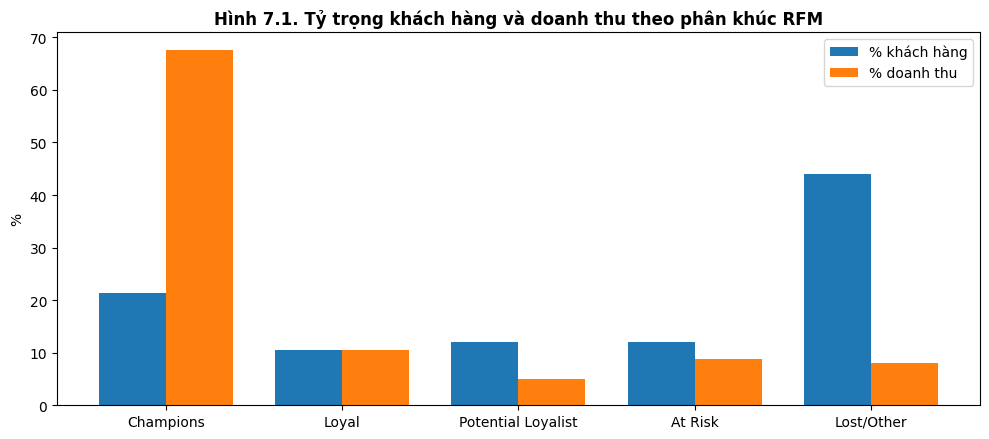

In [ ]:
# Biểu đồ: Tỷ trọng khách và doanh thu theo phân khúc
import numpy as np

seg_pd = seg_summary.toPandas()
x = np.arange(len(seg_pd)); width = 0.38

plt.figure(figsize=(10, 4.5))
plt.bar(x - width/2, seg_pd['CustShare_%'], width, label='% khách hàng')
plt.bar(x + width/2, seg_pd['RevShare_%'],  width, label='% doanh thu')
plt.xticks(x, seg_pd['Segment'])
plt.ylabel('%')
plt.title('Hình 7.1. Tỷ trọng khách hàng và doanh thu theo phân khúc RFM', fontweight='bold')
plt.legend(); plt.tight_layout(); plt.show()

In [ ]:
# Danh sách khách giá trị cao đang có nguy cơ rời bỏ
print('Bảng 7.3. Top 10 khách hàng At Risk có giá trị cao nhất')
rfm_segments.filter(F.col('Segment') == 'At Risk') \
    .select('CustomerID', 'Recency', 'Frequency',
            F.round('Monetary', 2).alias('Monetary'), 'RFMScore') \
    .orderBy(F.desc('Monetary')).show(10, truncate=False)

Bảng 7.3. Top 10 khách hàng At Risk có giá trị cao nhất
+----------+-------+---------+--------+--------+
|CustomerID|Recency|Frequency|Monetary|RFMScore|
+----------+-------+---------+--------+--------+
|12346     |325    |12       |77556.46|255     |
|16754     |372    |29       |67502.47|255     |
|17850     |372    |155      |56600.08|255     |
|13093     |275    |55       |54943.65|255     |
|15749     |235    |3        |44534.3 |235     |
|13902     |632    |5        |34095.26|145     |
|12482     |576    |29       |23691.4 |155     |
|14063     |438    |9        |22710.2 |155     |
|15808     |306    |21       |18409.93|255     |
|17448     |497    |46       |14556.97|155     |
+----------+-------+---------+--------+--------+
only showing top 10 rows


**Nhận xét Bảng 7.2:** Phân khúc khách hàng RFM

Tổng 5 phân khúc là 5.878 khách và £17.743.429,16, khớp với doanh thu từ khách có mã. Doanh thu bình quân mỗi khách là £3.018,62. Đây là con số đã sửa, thay cho £3.567,98 bị phóng đại ở phần KPI.

- Champions là trụ cột doanh thu. Nhóm này có 1.257 khách (21,38%) nhưng tạo ra £11.991.795,86, tức 67,58% doanh thu. Trung bình mỗi khách mua 17,4 lần, lần mua gần nhất cách ngày tham chiếu chỉ 19 ngày, và chi tiêu £9.540,01, gấp khoảng 17 lần nhóm Lost/Other.
- Champions và Loyal cộng lại chiếm khoảng 31,9% khách nhưng mang lại 78,2% doanh thu. Kết quả này khớp với phân tích tập trung ở bài tập 6 (Top 20% khách chiếm 77,26%).
- Loyal (620 khách, 10,61% doanh thu) mua khá đều (8,4 lần) nhưng lần mua gần nhất đã cách 85 ngày, lâu hơn nhiều so với Champions. Nhóm này cần được kích hoạt lại trước khi chuyển sang At Risk.
- Potential Loyalist (703 khách) mới mua gần đây (24 ngày) nhưng ít lần (2,9 lần) và chi tiêu thấp (£1.240,65). Đây là nhóm khách mới có thể nuôi dưỡng thành khách trung thành.
- At Risk là nhóm cần ưu tiên cứu. Có 708 khách từng mua khá thường xuyên (5,4 lần, chi tiêu trung bình £2.209,02) nhưng đã khoảng 360 ngày, gần một năm, không quay lại. Nhóm này nắm £1.563.985,75 (8,81%) doanh thu lịch sử.
- Lost/Other là nhóm đông nhất nhưng giá trị thấp nhất. Nhóm có 2.590 khách (44,06%) nhưng chỉ đóng góp 8,08% doanh thu. Phần lớn là khách mua 1–2 lần (trung bình 1,5 lần) rồi không quay lại (321 ngày).

**Nhận xét Bảng 7.3:** Khách At Risk giá trị cao

10 khách At Risk lớn nhất có tổng doanh thu £414.600,72, tức khoảng 26,5% doanh thu của cả nhóm At Risk. Giữ lại vài khách này mang lại hiệu quả cao hơn nhiều so với chăm sóc dàn trải 708 khách.

Khách 17850 đáng chú ý nhất. Đây là khách rất trung thành (155 đơn) với doanh thu £56.600,08, gấp khoảng 26 lần trung bình nhóm At Risk, nhưng đã 372 ngày không mua. Việc mất một khách mua thường xuyên như vậy cần được tìm hiểu nguyên nhân.

Khách 12346 đứng đầu bảng (£77.556,46). Doanh thu của khách này gần như đến từ đơn MEDIUM CERAMIC TOP STORAGE JAR 74.215 sản phẩm, đơn bất thường đã nêu ở câu 3. Nếu xác nhận đơn này bị hủy, giá trị thực của khách thấp hơn nhiều.

Hai kiểu khách At Risk:

- Khách mua nhiều lần (17850, 13093, 17448): đã có quan hệ lâu dài, có thể kích hoạt lại.
- Khách mua ít lần nhưng giá trị lớn (15749, 3 đơn, £44.534,30): khả năng là khách sỉ mua theo dự án hoặc theo mùa.
- Khách 13902 (632 ngày) và 12482 (576 ngày) đã ngừng mua gần 1,5–2 năm, nên khả năng quay lại thấp.

**Đề xuất hành động theo phân khúc**

| Phân khúc | Mục tiêu | Hành động |
| :--- | :--- | :--- |
| Champions | Giữ chân, tăng giá trị | Chương trình khách hàng VIP, người phụ trách riêng, ưu tiên hàng mới và hàng mùa lễ |
| Loyal | Tăng tần suất mua | Ưu đãi theo khối lượng, nhắc đặt hàng định kỳ trước mùa cao điểm tháng 9–11 |
| Potential Loyalist | Chuyển thành khách trung thành | Ưu đãi cho đơn thứ 3–4, gợi ý sản phẩm bán chạy (nhóm “xương sống” ở bài tập 4) |
| At Risk | Kéo khách quay lại | Liên hệ trực tiếp Top 10 trong Bảng 7.3, khảo sát lý do ngừng mua, ưu đãi quay lại có thời hạn |
| Lost/Other | Tối ưu chi phí | Email tự động chi phí thấp; không đầu tư nhiều nguồn lực |


## 10. Spark SQL

In [ ]:
sales.createOrReplaceTempView('sales')

In [ ]:
spark.sql('''
SELECT YearMonth,
       ROUND(SUM(Revenue), 2) AS Revenue,
       COUNT(DISTINCT InvoiceNo) AS Orders
FROM sales
GROUP BY YearMonth
ORDER BY YearMonth
''').show(30)

+---------+----------+------+
|YearMonth|   Revenue|Orders|
+---------+----------+------+
|  2009-12| 825685.76|  1682|
|  2010-01|  652708.5|  1105|
|  2010-02| 553339.74|  1201|
|  2010-03| 833570.13|  1681|
|  2010-04| 681528.99|  1462|
|  2010-05| 659858.86|  1500|
|  2010-06| 752270.14|  1645|
|  2010-07| 650712.94|  1529|
|  2010-08| 697274.91|  1425|
|  2010-09| 924333.01|  1839|
|  2010-10|1165483.91|  2301|
|  2010-11|1470272.48|  2747|
|  2010-12|1262598.79|  1559|
|  2011-01| 691364.56|  1086|
|  2011-02| 523631.89|  1100|
|  2011-03| 717639.36|  1454|
|  2011-04| 537808.62|  1246|
|  2011-05| 770536.02|  1681|
|  2011-06|  761739.9|  1533|
|  2011-07| 719221.19|  1475|
|  2011-08| 759138.38|  1361|
|  2011-09|1058590.17|  1837|
|  2011-10| 1154979.3|  2040|
|  2011-11|1509496.33|  2769|
|  2011-12| 638810.68|   819|
+---------+----------+------+



### Bài tập 8. Viết thêm 5 truy vấn SQL
1. Top 10 sản phẩm theo Revenue.
2. Top 10 khách hàng theo Revenue.
3. Top 10 quốc gia ngoài UK.
4. Tháng có AOV cao nhất.
5. Sản phẩm xuất hiện trong nhiều hóa đơn nhất.

In [ ]:
# TODO: Spark SQL queries

# Hàm in kèm tên bảng
def run_sql(title, query, n=10):
    print(title)
    spark.sql(query).show(n, truncate=False)

In [ ]:
# 1. Top 10 sản phẩm theo Revenue
run_sql('Bảng 8.1. Top 10 sản phẩm theo doanh thu (Spark SQL)', '''
SELECT StockCode,
       MAX(TRIM(Description))             AS Description,
       ROUND(SUM(Revenue), 2)             AS Revenue,
       SUM(Quantity)                      AS Units,
       COUNT(DISTINCT InvoiceNo)          AS Orders
FROM sales
WHERE StockCode RLIKE '^[0-9]{5}'          -- chỉ giữ mã sản phẩm thật, loại M, DOT, POST...
GROUP BY StockCode
ORDER BY Revenue DESC
LIMIT 10
''')

Bảng 8.1. Top 10 sản phẩm theo doanh thu (Spark SQL)
+---------+----------------------------------+---------+-----+------+
|StockCode|Description                       |Revenue  |Units|Orders|
+---------+----------------------------------+---------+-----+------+
|22423    |REGENCY CAKESTAND 3 TIER          |344563.25|27577|3918  |
|85123A   |WHITE HANGING HEART T-LIGHT HOLDER|263109.67|96147|5365  |
|85099B   |RED RETROSPOT JUMBO BAG           |183454.83|98349|3989  |
|23843    |PAPER CRAFT , LITTLE BIRDIE       |168469.6 |80995|1     |
|47566    |PARTY BUNTING                     |149187.05|28378|2674  |
|84879    |ASSORTED COLOUR BIRD ORNAMENT     |132187.92|81809|2807  |
|22086    |PAPER CHAIN KIT 50'S CHRISTMAS    |123141.54|36581|2018  |
|79321    |CHILLI LIGHTS                     |85489.91 |16840|1135  |
|23166    |MEDIUM CERAMIC TOP STORAGE JAR    |81700.92 |78033|247   |
|22197    |SMALL POPCORN HOLDER              |80920.64 |89898|2322  |
+---------+--------------------------

In [ ]:
# 2. Top 10 khách hàng theo Revenue
run_sql('Bảng 8.2. Top 10 khách hàng theo doanh thu (Spark SQL)', '''
SELECT CAST(CustomerID AS INT)            AS CustomerID,
       FIRST(Country)                     AS Country,
       ROUND(SUM(Revenue), 2)             AS Revenue,
       COUNT(DISTINCT InvoiceNo)          AS Orders,
       ROUND(SUM(Revenue) / COUNT(DISTINCT InvoiceNo), 2) AS AOV
FROM sales
WHERE CustomerID IS NOT NULL
GROUP BY CustomerID
ORDER BY Revenue DESC
LIMIT 10
''')

Bảng 8.2. Top 10 khách hàng theo doanh thu (Spark SQL)
+----------+--------------+---------+------+--------+
|CustomerID|Country       |Revenue  |Orders|AOV     |
+----------+--------------+---------+------+--------+
|18102     |United Kingdom|608821.65|145   |4198.77 |
|14646     |Netherlands   |528602.52|151   |3500.68 |
|14156     |EIRE          |313946.37|156   |2012.48 |
|14911     |EIRE          |295972.63|398   |743.65  |
|17450     |United Kingdom|246973.09|51    |4842.61 |
|13694     |United Kingdom|196482.81|143   |1374.01 |
|17511     |United Kingdom|175603.55|60    |2926.73 |
|16446     |United Kingdom|168472.5 |2     |84236.25|
|16684     |United Kingdom|147142.77|55    |2675.32 |
|12415     |Australia     |144458.37|28    |5159.23 |
+----------+--------------+---------+------+--------+



In [ ]:
# 3. Top 10 quốc gia ngoài UK
run_sql('Bảng 8.3. Top 10 quốc gia ngoài UK theo doanh thu (Spark SQL)', '''
SELECT Country,
       ROUND(SUM(Revenue), 2)             AS Revenue,
       COUNT(DISTINCT InvoiceNo)          AS Orders,
       COUNT(DISTINCT CustomerID)         AS Customers,
       ROUND(SUM(Revenue) / COUNT(DISTINCT InvoiceNo), 2) AS AOV
FROM sales
WHERE Country NOT IN ('United Kingdom', 'Unspecified')
GROUP BY Country
ORDER BY Revenue DESC
LIMIT 10
''')

Bảng 8.3. Top 10 quốc gia ngoài UK theo doanh thu (Spark SQL)
+-----------+---------+------+---------+-------+
|Country    |Revenue  |Orders|Customers|AOV    |
+-----------+---------+------+---------+-------+
|EIRE       |664431.78|626   |5        |1061.39|
|Netherlands|554232.34|228   |22       |2430.84|
|Germany    |431262.46|789   |107      |546.59 |
|France     |356944.6 |622   |95       |573.87 |
|Australia  |169968.11|95    |15       |1789.14|
|Spain      |109178.53|154   |41       |708.95 |
|Switzerland|101011.29|93    |22       |1086.14|
|Sweden     |91903.72 |105   |19       |875.27 |
|Denmark    |69862.19 |43    |12       |1624.7 |
|Belgium    |65753.42 |149   |29       |441.3  |
+-----------+---------+------+---------+-------+



In [ ]:
# 4. Tháng có AOV cao nhất
run_sql('Bảng 8.4. Xếp hạng tháng theo AOV (Spark SQL)', '''
SELECT YearMonth,
       ROUND(SUM(Revenue), 2)             AS Revenue,
       COUNT(DISTINCT InvoiceNo)          AS Orders,
       ROUND(SUM(Revenue) / COUNT(DISTINCT InvoiceNo), 2) AS AOV,
       RANK() OVER (ORDER BY SUM(Revenue) / COUNT(DISTINCT InvoiceNo) DESC) AS AOV_Rank
FROM sales
GROUP BY YearMonth
ORDER BY AOV DESC
LIMIT 5
''', n=5)

Bảng 8.4. Xếp hạng tháng theo AOV (Spark SQL)
+---------+----------+------+------+--------+
|YearMonth|Revenue   |Orders|AOV   |AOV_Rank|
+---------+----------+------+------+--------+
|2010-12  |1262598.79|1559  |809.88|1       |
|2011-12  |638810.68 |819   |779.99|2       |
|2011-01  |691364.56 |1086  |636.62|3       |
|2010-01  |652708.5  |1105  |590.69|4       |
|2011-09  |1058590.17|1837  |576.26|5       |
+---------+----------+------+------+--------+



In [ ]:
# 5. Sản phẩm xuất hiện trong nhiều hóa đơn nhất
run_sql('Bảng 8.5. Top 10 sản phẩm xuất hiện trong nhiều hóa đơn nhất (Spark SQL)', '''
WITH total AS (
    SELECT COUNT(DISTINCT InvoiceNo) AS TotalOrders
    FROM sales
    WHERE StockCode RLIKE '^[0-9]{5}'
)
SELECT s.StockCode,
       MAX(TRIM(s.Description))           AS Description,
       COUNT(DISTINCT s.InvoiceNo)        AS Orders,
       ROUND(COUNT(DISTINCT s.InvoiceNo) / MAX(t.TotalOrders) * 100, 2) AS Penetration_pct
FROM sales s
CROSS JOIN total t
WHERE s.StockCode RLIKE '^[0-9]{5}'
GROUP BY s.StockCode
ORDER BY Orders DESC
LIMIT 10
''')

Bảng 8.5. Top 10 sản phẩm xuất hiện trong nhiều hóa đơn nhất (Spark SQL)
+---------+----------------------------------+------+---------------+
|StockCode|Description                       |Orders|Penetration_pct|
+---------+----------------------------------+------+---------------+
|85123A   |WHITE HANGING HEART T-LIGHT HOLDER|5365  |13.58          |
|85099B   |RED RETROSPOT JUMBO BAG           |3989  |10.09          |
|22423    |REGENCY CAKESTAND 3 TIER          |3918  |9.91           |
|21212    |PACK OF 72 RETROSPOT CAKE CASES   |3118  |7.89           |
|20725    |LUNCH BAG RED SPOTTY              |3056  |7.73           |
|84879    |ASSORTED COLOUR BIRD ORNAMENT     |2807  |7.1            |
|47566    |PARTY BUNTING                     |2674  |6.77           |
|21232    |STRAWBERRY CERAMIC TRINKET POT    |2435  |6.16           |
|22383    |LUNCHBAG SUKI  DESIGN             |2398  |6.07           |
|20727    |LUNCH BAG  BLACK SKULL.           |2351  |5.95           |
+---------+------

## 11. Pareto 80/20

In [ ]:
total_product_revenue = product_sales.agg(F.sum('Revenue')).first()[0]
w = Window.orderBy(F.desc('Revenue')).rowsBetween(Window.unboundedPreceding, Window.currentRow)
pareto_products = (product_sales
    .orderBy(F.desc('Revenue'))
    .withColumn('CumRevenue', F.sum('Revenue').over(w))
    .withColumn('CumShare', F.col('CumRevenue') / F.lit(total_product_revenue)))
pareto_products.show(20, truncate=False)

+---------+-----------------------------------+------------------+-----+------+------------------+--------------------+
|StockCode|Description                        |Revenue           |Units|Orders|CumRevenue        |CumShare            |
+---------+-----------------------------------+------------------+-----+------+------------------+--------------------+
|22423    |REGENCY CAKESTAND 3 TIER           |344563.25000000064|27577|3918  |344563.25000000064|0.016429214272121326|
|M        |Manual                             |340716.28000000026|10050|784   |685279.530000001  |0.03267500011875494 |
|DOT      |DOTCOM POSTAGE                     |322657.4800000002 |1436 |1415  |1007937.0100000012|0.04805971939866275 |
|85123A   |WHITE HANGING HEART T-LIGHT HOLDER |262931.1599999977 |96086|5356  |1270868.169999999 |0.06059661172962774 |
|23843    |PAPER CRAFT , LITTLE BIRDIE        |168469.6          |80995|1     |1439337.769999999 |0.06862945666227382 |
|47566    |PARTY BUNTING                

### Câu hỏi
Bao nhiêu % sản phẩm tạo ra 80% doanh thu? Có thực sự là quy luật 80/20 không? Lặp lại phân tích cho khách hàng.

In [ ]:
# Phân tích Pareto cho sản phẩm và khách hàng
import math

def pareto_table(df, key, value='Revenue'):
    """Xếp hạng, tính tỷ trọng tích lũy theo doanh thu và theo số phần tử."""
    total = df.agg(F.sum(value)).first()[0]
    n = df.count()
    w = Window.orderBy(F.desc(value), F.col(key))
    out = (df
        .withColumn('Rank', F.row_number().over(w))
        .withColumn('CumShare_%', F.sum(value).over(w.rowsBetween(Window.unboundedPreceding,
                                                                  Window.currentRow)) / F.lit(total) * 100)
        .withColumn('ItemShare_%', F.col('Rank') / F.lit(n) * 100)
        .cache())
    return out, n

def pareto_summary(df, n, label):
    rows = []
    for target in [50, 80, 90]:                                  # cần bao nhiêu % phần tử để đạt x% doanh thu
        r = df.filter(F.col('CumShare_%') >= target).orderBy('Rank').first()
        rows.append((label, f'{target}% doanh thu', int(r['Rank']), round(r['ItemShare_%'], 2)))
    k = math.ceil(n * 0.2)                                       # top 20% phần tử chiếm bao nhiêu doanh thu
    r = df.filter(F.col('Rank') == k).first()
    rows.append((label, 'Top 20% phần tử', k, round(r['CumShare_%'], 2)))
    return rows

pareto_prod, n_prod = pareto_table(product_clean, 'StockCode')
pareto_cust, n_cust = pareto_table(cust.withColumn('CustomerID', F.col('CustomerID').cast('int')), 'CustomerID')

rows = pareto_summary(pareto_prod, n_prod, 'Sản phẩm') + pareto_summary(pareto_cust, n_cust, 'Khách hàng')
pareto_df = spark.createDataFrame(rows, ['Đối tượng', 'Mốc', 'Số phần tử', 'Tỷ lệ_%'])

print(f'Số sản phẩm: {n_prod:,} | Số khách hàng: {n_cust:,}')
print('Bảng 11.1. Phân tích Pareto cho sản phẩm và khách hàng')
print('(Với các mốc "x% doanh thu": Tỷ lệ_% = % số phần tử cần có. Với "Top 20%": Tỷ lệ_% = % doanh thu đạt được)')
pareto_df.show(truncate=False)

Số sản phẩm: 4,878 | Số khách hàng: 5,878
Bảng 11.1. Phân tích Pareto cho sản phẩm và khách hàng
(Với các mốc "x% doanh thu": Tỷ lệ_% = % số phần tử cần có. Với "Top 20%": Tỷ lệ_% = % doanh thu đạt được)
+----------+---------------+----------+-------+
|Đối tượng |Mốc            |Số phần tử|Tỷ lệ_%|
+----------+---------------+----------+-------+
|Sản phẩm  |50% doanh thu  |284       |5.82   |
|Sản phẩm  |80% doanh thu  |1036      |21.24  |
|Sản phẩm  |90% doanh thu  |1696      |34.77  |
|Sản phẩm  |Top 20% phần tử|976       |78.69  |
|Khách hàng|50% doanh thu  |259       |4.41   |
|Khách hàng|80% doanh thu  |1353      |23.02  |
|Khách hàng|90% doanh thu  |2342      |39.84  |
|Khách hàng|Top 20% phần tử|1176      |77.26  |
+----------+---------------+----------+-------+



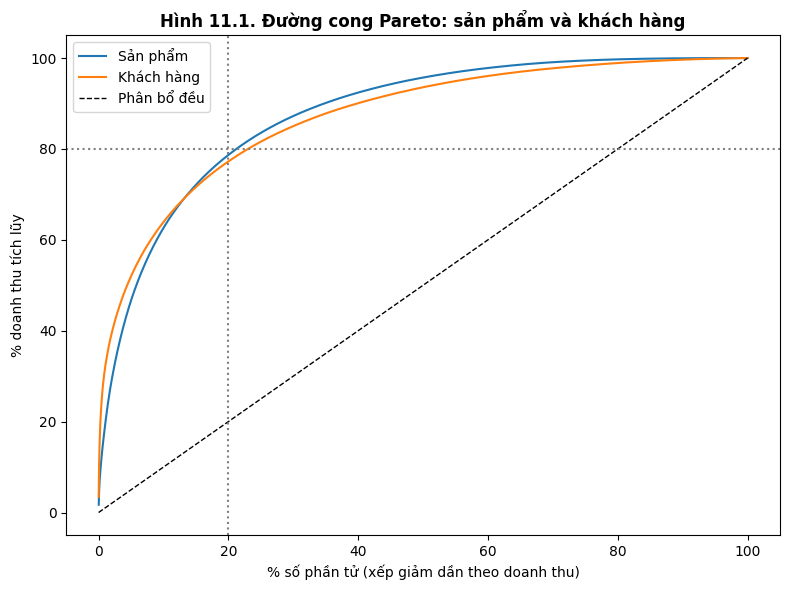

In [ ]:
# Biểu đồ đường Pareto
prod_pd = pareto_prod.select('ItemShare_%', 'CumShare_%').orderBy('ItemShare_%').toPandas()
cust_pd = pareto_cust.select('ItemShare_%', 'CumShare_%').orderBy('ItemShare_%').toPandas()

plt.figure(figsize=(8, 6))
plt.plot(prod_pd['ItemShare_%'], prod_pd['CumShare_%'], label='Sản phẩm')
plt.plot(cust_pd['ItemShare_%'], cust_pd['CumShare_%'], label='Khách hàng')
plt.plot([0, 100], [0, 100], 'k--', linewidth=1, label='Phân bổ đều')
plt.axhline(80, color='gray', linestyle=':'); plt.axvline(20, color='gray', linestyle=':')
plt.xlabel('% số phần tử (xếp giảm dần theo doanh thu)')
plt.ylabel('% doanh thu tích lũy')
plt.title('Hình 11.1. Đường cong Pareto: sản phẩm và khách hàng', fontweight='bold')
plt.legend(); plt.tight_layout(); plt.show()

1. **Bao nhiêu % sản phẩm tạo ra 80% doanh thu?**

80% doanh thu sản phẩm đến từ 1.036 mã, tức 21,24% số sản phẩm. Đọc theo chiều ngược lại, Top 20% sản phẩm (976 mã) tạo ra 78,69% doanh thu.

2. **Có thực sự là quy luật 80/20 không?**

Có, khá sát. Ở cả hai chiều đọc, kết quả chỉ lệch khoảng 1–1,3 điểm phần trăm so với tỷ lệ 20/80 lý tưởng. Tuy vậy, đường cong không đều ở các đoạn khác nhau:

- Phần đầu tập trung mạnh: chỉ 5,82% sản phẩm (284 mã) đã tạo ra một nửa doanh thu.
- Phần đuôi rất dài: để đạt 90% doanh thu cần 34,77% sản phẩm. Nghĩa là khoảng 65% số mã còn lại chỉ đóng góp 10% doanh thu.

Vì vậy, 80/20 ở đây đúng như một quy luật kinh nghiệm tại mốc 80%. Không nên hiểu nó là tỷ lệ cố định ở mọi điểm trên đường cong.

3. **Lặp lại phân tích cho khách hàng**

| Mốc | Sản phẩm | Khách hàng |
| :--- | :--- | :--- |
| Đạt 50% doanh thu | 5,82% (284 mã) | 4,41% (259 khách) |
| Đạt 80% doanh thu | 21,24% (1.036 mã) | 23,02% (1.353 khách) |
| Đạt 90% doanh thu | 34,77% (1.696 mã) | 39,84% (2.342 khách) |
| Doanh thu của Top 20% | 78,69% | 77,26% |

Khách hàng cũng gần đúng quy luật 80/20: 23,02% khách tạo ra 80% doanh thu, và Top 20% khách chiếm 77,26%.

Ở nhóm đầu, khách hàng tập trung hơn sản phẩm. Chỉ 4,41% khách đã tạo ra 50% doanh thu, so với 5,82% sản phẩm. Một khách lớn đơn lẻ (ví dụ 18102, khoảng 3,4% doanh thu) có trọng số lớn hơn nhiều so với sản phẩm lớn nhất (1,71%).

Từ mốc 80% trở đi, sản phẩm lại tập trung hơn khách hàng. Đuôi sản phẩm dài và “mỏng” hơn: 34,77% sản phẩm đã đạt 90% doanh thu, trong khi khách hàng cần 39,84%.

4. **Hàm ý kinh doanh**

Sản phẩm:
- Khoảng 1.036 mã chủ lực cần ưu tiên tồn kho, không để hết hàng, đặc biệt trước mùa cao điểm tháng 9–11.
- Khoảng 65% số mã chỉ đóng góp 10% doanh thu. Nên rà soát nhóm này để cắt giảm mã bán chậm (SKU rationalization), giảm chi phí lưu kho và quản lý.

Khách hàng:
- 259 khách tạo ra một nửa doanh thu là nhóm cần chăm sóc riêng (key account), nhất là những khách đang nằm trong phân khúc At Risk ở Bảng 7.3.
- Rủi ro mất khách lớn có tác động mạnh hơn rủi ro mất một sản phẩm lớn.

## 12. Executive Summary: Sinh viên phải hoàn thành
Viết ngắn gọn:
1. **5 insights quan trọng nhất**.
- Insight 1 – Quy mô dữ liệu lớn, cần xử lý và làm sạch
- Insight 2 – Doanh thu có tính mùa vụ, tăng mạnh vào cuối năm
- Insight 3 – Một số sản phẩm đóng góp doanh thu nổi bật
- Insight 4 – Doanh thu tập trung vào nhóm khách hàng Champions
- Insight 5 – Phân phối doanh thu gần với quy luật Pareto 80/20
2. **3 hành động kinh doanh** dựa trên dữ liệu.
- Ưu tiên giữ chân khách hàng giá trị cao
- Tối ưu tồn kho và chương trình bán hàng theo mùa
- Tập trung nguồn lực vào sản phẩm và thị trường hiệu quả
3. **2 hạn chế của dataset/phân tích**.
Hạn chế 1 – Dữ liệu khách hàng thiếu và có giao dịch bất thường.
- Có 243.007/1.067.371 dòng thiếu CustomerID, tương đương khoảng 22,76% dữ liệu gốc. Những dòng này không thể được gán chính xác vào phân tích RFM theo khách hàng.
- Có 19.494 dòng mang mã hóa đơn hủy, cùng với các dòng có Quantity hoặc UnitPrice không hợp lệ. Việc loại bỏ dữ liệu có thể làm thay đổi kết quả doanh thu; các quy tắc làm sạch cần được kiểm tra và ghi nhận rõ.
Hạn chế 2 – Chưa đánh giá đầy đủ lợi nhuận và khả năng dự báo.
- Dataset không cung cấp đầy đủ giá vốn và chi phí vận hành, nên doanh thu cao không đồng nghĩa lợi nhuận cao.
- Phân tích RFM và xu hướng lịch sử mô tả hành vi trong quá khứ, chưa chứng minh quan hệ nhân quả hoặc dự báo chính xác doanh thu tương lai.


## 13. Câu hỏi thảo luận
1. Vì sao không nên `toPandas()` toàn bộ dataset?

Trả lời: toPandas() chuyển dữ liệu từ Spark DataFrame sang Pandas DataFrame. Khi thực hiện, dữ liệu sẽ được thu thập về bộ nhớ của máy tính điều khiển Spark (driver), thay vì tiếp tục được phân tán trên các máy xử lý.

Có ba lý do chính không nên chuyển toàn bộ dataset:
- Giới hạn RAM: Nếu dữ liệu quá lớn, bộ nhớ không đủ có thể khiến chương trình bị lỗi OutOfMemoryError.
- Mất lợi thế xử lý phân tán: Spark có thể xử lý dữ liệu trên nhiều partition, trong khi Pandas thường xử lý dữ liệu trong bộ nhớ của một máy.
- Giảm khả năng mở rộng: Dataset càng lớn thì việc chuyển toàn bộ dữ liệu về Pandas càng tốn tài nguyên và thời gian.
Ví dụ: Với dữ liệu 100 triệu dòng, nên dùng Spark để lọc, tổng hợp doanh thu theo tháng hoặc theo khách hàng trước. Sau đó, chỉ chuyển bảng kết quả nhỏ sang Pandas để vẽ biểu đồ.
2. Vì sao phải giữ riêng thông tin giao dịch hủy thay vì xóa ngay từ đầu?
Trả lời:

Giao dịch hủy là một phần thông tin quan trọng giúp đánh giá tình hình kinh doanh. Nếu xóa ngay từ đầu, chúng ta sẽ mất khả năng phân tích tỷ lệ hủy đơn, hành vi khách hàng và những nguyên nhân có thể làm giảm doanh thu.

Ba lợi ích chính:
+ Đánh giá tỷ lệ hủy: Xác định số lượng và tỷ trọng giao dịch bị hủy so với tổng số giao dịch.
+ Phân tích hành vi khách hàng: Xem khách hàng nào thường xuyên hủy đơn, từ đó xác định nhóm cần theo dõi.
+ Đảm bảo tính linh hoạt: Có thể xây dựng báo cáo doanh thu thực tế bằng cách loại giao dịch hủy, đồng thời vẫn giữ dữ liệu để phân tích rủi ro.
Ví dụ, trong bộ dữ liệu bán hàng, mã hóa đơn bắt đầu bằng chữ C có thể được dùng để nhận diện giao dịch hủy nếu đúng với quy ước của dataset. Khi đó, nên tạo hai tập dữ liệu hoặc một cột trạng thái giao dịch, thay vì xóa ngay các dòng này.

Lưu ý: Giao dịch hủy cần được loại khỏi chỉ tiêu doanh thu bán hàng thực tế khi phù hợp với định nghĩa nghiệp vụ, nhưng không nhất thiết phải loại khỏi mọi phân tích.
3. RFM có hạn chế gì?
Trả lời:

RFM là mô hình phân nhóm khách hàng dựa trên ba tiêu chí:
- R – Recency: Khoảng thời gian từ lần mua hàng gần nhất đến ngày phân tích. Khách mua càng gần đây thường có điểm R càng cao.
- F – Frequency: Tần suất mua hàng của khách hàng trong một khoảng thời gian.
- M – Monetary: Tổng giá trị tiền khách hàng đã chi tiêu trong khoảng thời gian phân tích.
Tuy nhiên, RFM có một số hạn chế:
- Không phản ánh lợi nhuận thực tế: Khách hàng có doanh thu cao chưa chắc mang lại lợi nhuận cao nếu chi phí phục vụ hoặc giá vốn lớn.
- Phụ thuộc vào dữ liệu lịch sử: Mô hình chưa chắc dự đoán chính xác hành vi mua hàng trong tương lai.
- Nhạy cảm với cách tính toán: Kết quả phân nhóm có thể thay đổi theo thời gian phân tích, cách chia điểm và cách xử lý giao dịch hủy.
- Không giải thích nguyên nhân hành vi: RFM cho biết khách hàng mua nhiều hay ít nhưng không cho biết tại sao họ mua hoặc ngừng mua.
Ví dụ: Hai khách hàng đều chi tiêu 10 triệu đồng, nhưng một người mua thường xuyên với giá trị nhỏ, còn người kia chỉ mua một đơn hàng lớn. Điểm RFM có thể giúp phân biệt hành vi của hai người, nhưng chưa thể xác định chính xác lợi nhuận mà mỗi người mang lại nếu không có dữ liệu chi phí.

Kết luận: Nên kết hợp RFM với dữ liệu lợi nhuận, sản phẩm, kênh bán hàng và mô hình dự báo để nâng cao chất lượng quyết định kinh doanh.
4. Nếu dữ liệu tăng lên 100 triệu dòng, đâu là lợi thế của Spark?
Trả lời:

Khi dữ liệu tăng lên 100 triệu dòng, Apache Spark có lợi thế nhờ khả năng xử lý phân tán và thực hiện các phép biến đổi dữ liệu trên nhiều partition.

Các lợi thế chính gồm:
- Xử lý song song: Phân chia dữ liệu thành nhiều phần để các executor xử lý đồng thời.
- Mở rộng tài nguyên: Có thể tăng tài nguyên hoặc số máy trong cụm xử lý khi cần thiết.
- Tối ưu truy vấn: Spark SQL có thể tối ưu kế hoạch thực thi và các phép lọc, nhóm, tổng hợp dữ liệu.
- Hỗ trợ phân tích dữ liệu lớn: Phù hợp với việc tính doanh thu, phân nhóm khách hàng RFM và phân tích xu hướng bán hàng trên dataset lớn.
Ví dụ, khi phân tích 100 triệu giao dịch, Spark có thể tính tổng doanh thu theo khách hàng bằng groupBy() và agg() mà không cần chuyển toàn bộ dữ liệu về Pandas.
5. Nếu có thêm cost/profit, bài phân tích nên thay đổi thế nào?
Trả lời: Phân tích thêm lợi nhuận, biên lợi nhuận và hiệu quả theo sản phẩm, khách hàng để hỗ trợ quyết định kinh doanh tốt hơn.

# Kết thúc